<a href="https://colab.research.google.com/github/SamsGibsP/TI4006_GA/blob/main/P11_Hands_on_GA_TSP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hands-on Pertemuan 11 — Genetic Algorithm untuk TSP
**TI 4006 Algoritma Optimisasi dan Metaheuristik**

Hands-on ini menggunakan kode **TSP – Genetic Algorithm** yang telah tersedia dan mengembangkannya secara bertahap.

| Tahap | Isi |
|---|---|
| 1 | Penelusuran manual GA berukuran kecil (10 simpul, 2 generasi) |
| 2 | Eksekusi GA 50 pelanggan (kode asli) |
| 3 | Pengukuran waktu komputasi (profiling) |
| 4 | Riwayat konvergensi, elitisme, fungsi eksperimen |
| 5 | Operator lain: order crossover (OX) dan inversion mutation |
| 6 | Rancangan eksperimen: seed, beberapa eksekusi, anggaran yang setara |
| 7 | GA + 2-opt (memetic algorithm) |
| – | Tantangan kelas: satu modifikasi sendiri |
| 8 | Instance TSPLIB (persiapan Tugas GA) |

Kode asli tidak diubah. Setiap perubahan ditulis sebagai fungsi baru dan ditandai `# BARU`.
Latihan ditandai dengan ✏️.

## Tahap 1 — Penelusuran GA berukuran kecil

Sel berikut merupakan kode asli versi kecil (10 simpul, populasi 10, setiap langkah dicetak). Seed ditetapkan agar seluruh mahasiswa memperoleh keluaran yang sama.

Pseudocode yang diimplementasikan oleh kode ini:
```
1. P <- populasi awal (permutasi simpul 1..n-1; simpul 0 = depot, tetap di awal dan akhir)
2. evaluasi: jarak total, fitness = 1 / jarak total
3. ULANGI untuk setiap generasi :
3.1   ULANGI ukuran_populasi/2 kali :
         induk1, induk2 <- seleksi turnamen
         dengan peluang crossover_rate : anak1, anak2 <- position-based crossover
         dengan peluang mutation_rate  : swap mutation pada tiap anak
3.2   P <- semua anak                       (generational, tanpa elitisme)
3.3   evaluasi P, perbarui solusi terbaik sepanjang run
```

In [1]:
import random as rd
import numpy as np
rd.seed(11); np.random.seed(11)    # BARU: seed agar keluaran seragam di seluruh kelas

In [2]:
# Genetic Algoritthm untuk TSP

import numpy as np
import random as rd
import matplotlib.pyplot as plt
import time

"""
# Data
jarak = [
  [ 0,  9, 14, 10, 20, 11, 15, 17,  8,  3],
  [ 8,  0, 17,  4, 13,  8,  5,  1,  5, 14],
  [ 9, 17,  0, 16, 10, 14,  3,  8,  4,  5],
  [ 9, 19,  1,  0,  8,  4, 19,  6, 14, 12],
  [10,  5, 19, 10,  0, 15, 12, 19, 17,  7],
  [16, 19,  1, 17,  2,  0,  2,  3, 18, 10],
  [13, 17,  3, 18,  8, 18,  0,  4, 17,  5],
  [ 8,  6,  4, 16, 11,  6, 17,  0,  4, 11],
  [17, 15, 20,  2,  2,  7, 12,  9,  0, 17],
  [17,  2,  6,  8, 20, 10,  6, 15,  4,  0]]
jumlah_simpul = len(jarak)
daftar_simpul = list(range(jumlah_simpul))
"""

jumlah_simpul = 10
xsimpul = jumlah_simpul**2 - jumlah_simpul
daftar = list(range(1,xsimpul+1))
a = rd.sample(daftar,xsimpul)
print(a)
jarak = np.zeros((jumlah_simpul,jumlah_simpul))
k = 0
for i in range(jumlah_simpul):
    for j in range(jumlah_simpul):
        if i != j:
            jarak[i][j] = a[k]
            k += 1
daftar_simpul = list(range(jumlah_simpul))

print(daftar_simpul)

# Parameter-parameter algoritma:
ukuran_populasi = 100
crossover_rate = 0.7
mutation_rate = 0.1
max_generation = 3

# parameter-paramater masalah:
panjang_kromosom = jumlah_simpul - 1
ukuran_turnamen = 5 # Define ukuran_turnamen

# pembangkitan populasi awal
def pembangkitan_populasi_awal(ukuran_populasi, jumlah_titik, panjang_kromosom):
    populasi = []
    for _ in range(ukuran_populasi):
        simpul_tersedia = daftar_simpul[1:]
        kromosom = rd.sample(simpul_tersedia, jumlah_titik - 1)
        populasi.append(kromosom)

    return populasi

# proses dekoding, penentuan nilai fungsi tujuan, dan nilai fitnes
def evalusi_populasi(ukuran_populasi, kromosom, panjang_kromosom, jarak):

    # Bangun solusi dari kromosom
    solusi = [[0] * (panjang_kromosom + 2) for _ in range(ukuran_populasi)]
    total_jarak = [0.0] * ukuran_populasi
    fitness = [0.0] * ukuran_populasi
    for p in range(ukuran_populasi):
        solusi[p] = [0] + list(map(int, kromosom[p])) + [0] # Tambah titik nol, syarat TSP

    # Hitung total jarak
    for p in range(ukuran_populasi):
        total_jarak[p] = sum(jarak[solusi[p][j]][solusi[p][j + 1]] for j in range(len(solusi[p]) - 1))

    # Hitung fitness
    for p in range(ukuran_populasi):
        # fitness = 1 / jarak total
        fitness[p] = 1 / total_jarak[p] if total_jarak[p] != 0 else 0

    # Cari solusi terbaik pada popuplasi
    p_best = np.argmax(fitness) # maksimisasi fitness (minimisasi jarak total)
    best_solusi = solusi[p_best]
    best_fitness = fitness[p_best]

    return solusi, total_jarak, fitness, p_best


# Seleksi Turnamem
def seleksi_turnamen(ukuran_populasi, x_populasi, nilai_fitness, ukuran_turnamen): # Added ukuran_turnamen as argument
    # membuat list yang berisi indeks calon induk sebanyak ukuran turnamen
    indeks_parent_terpilih = rd.sample(range(ukuran_populasi), ukuran_turnamen)
    kandidat = [(x_populasi[i], nilai_fitness[i]) for i in indeks_parent_terpilih]

    for i in range(len(indeks_parent_terpilih)):
        print(f'calon: {kandidat[i][0]} nilai fitnes = {kandidat[i][1]:.4f}')

    kandidat.sort(key=lambda x: x[1], reverse=True) # urutkan berdasarkan fitness (kasus maksimisasi)
    parent = kandidat[0][0] # pilih pada urutan pertama

    return parent

def position_based_crossover(induk1, induk2): # Removed unnecessary arguments
    panjang_kromosom = len(induk1)
    anak1 = [None] * panjang_kromosom
    anak2 = [None] * panjang_kromosom
    jumlah_posisi_yang_dipilih = np.random.randint(1, panjang_kromosom) # Jumlah yang akan ditukar Random => Bisa saja posisi yang dipilih tidak ada sehingga tidak terjadi pertukaran, lanjut tanpa mutasi
    posisi_yang_dipilih = np.random.choice(panjang_kromosom, jumlah_posisi_yang_dipilih, replace=False) # Posisi yang akan ditukar
    posisi_yang_dipilih.sort()

    for posisi in posisi_yang_dipilih:
        anak1[posisi] = induk1[posisi]
    sisa_gen_induk2 = [gen for gen in induk2 if gen not in [anak1[pos] for pos in posisi_yang_dipilih]]
    indeks_sisa_gen = 0
    for i in range(panjang_kromosom):
        if anak1[i] is None:
            anak1[i] = sisa_gen_induk2[indeks_sisa_gen]
            indeks_sisa_gen += 1

    for posisi in posisi_yang_dipilih:
        anak2[posisi] = induk2[posisi]
    sisa_gen_induk1 = [gen for gen in induk1 if gen not in [anak2[pos] for pos in posisi_yang_dipilih]]
    indeks_sisa_gen = 0
    for i in range(panjang_kromosom):
        if anak2[i] is None:
            anak2[i] = sisa_gen_induk1[indeks_sisa_gen]
            indeks_sisa_gen += 1



    return anak1, anak2

def swap_mutation(kromosom): # Removed unnecessary arguments, mana yang mau ditukar
    panjang_kromosom = len(kromosom)
    idx1 = rd.randint(0,panjang_kromosom-1)
    idx2 = rd.randint(0,panjang_kromosom-1)
    while idx2 == idx1:
        idx2 = rd.randint(0,panjang_kromosom-1)
    kromosom[idx1], kromosom[idx2] = kromosom[idx2], kromosom[idx1]
    return kromosom

# fungsi reproduksi
def reproduksi(ukuran_populasi, populasi, nilai_fitness, crossover_rate, mutation_rate, ukuran_turnamen): # Added ukuran_turnamen as argument

    populasi_lama = populasi.copy()
    populasi_baru  = []

    for _ in range(ukuran_populasi // 2):
        # Seleksi turnamen
        print(f'seleksi')

        induk1 = seleksi_turnamen(ukuran_populasi, populasi_lama, nilai_fitness, ukuran_turnamen) # Added comma and ukuran_turnamen
        print(f'Induk 1 {induk1}')

        induk2 = seleksi_turnamen(ukuran_populasi, populasi_lama, nilai_fitness, ukuran_turnamen) # Added ukuran_turnamen
        print(f'Induk 2 {induk2}')

        # Persilangan
        print(f'persilangan')
        if np.random.random() < crossover_rate:
            anak1, anak2 = position_based_crossover(induk1, induk2)
        else:
            anak1, anak2 = induk1.copy(), induk2.copy()
        print(f'anak 1 {anak1}')
        print(f'anak 2 {anak2}')

        # Mutasi
        print(f'mutasi')
        if np.random.random() < mutation_rate:
            anak1 = swap_mutation(anak1) # lakukan mutasi
        print(f'anak 1 {anak1}')
        if np.random.random() < mutation_rate:
            anak2 = swap_mutation(anak2) # lakukan mutasi
        print(f'anak 2 {anak2}')

        # Pembaruan populasi
        populasi_baru.append(anak1)
        populasi_baru.append(anak2)

    return populasi_baru

def genetic_algorithm_tsp(jarak, jumlah_simpul, ukuran_populasi, crossover_rate, mutation_rate, max_generation, ukuran_turnamen): # Added ukuran_turnamen as argument
    gen = 0

    populasi = pembangkitan_populasi_awal(ukuran_populasi, jumlah_simpul, panjang_kromosom)

    print('Populasi awal')
    for i in range(len(populasi)):
        populasi[i] = list(map(int, populasi[i]))
        print(populasi[i])
    print()

    # Evaluasi populasi
    solusi, total_jarak, fitness, p_best = evalusi_populasi(ukuran_populasi, populasi, panjang_kromosom, jarak)

    # Inisialisasi best solution
    best_idx = np.argmax(fitness)
    best_solusi = solusi[best_idx]
    best_fitness = fitness[best_idx]

    while gen <= max_generation:
        gen += 1
        # Reproduksi (seleksi, persilangan, mutasi)
        populasi = reproduksi(ukuran_populasi, populasi, fitness, crossover_rate, mutation_rate, ukuran_turnamen)

        print(f'Generasi: {gen}')
        print('Populasi:')
        for i in range(len(populasi)):
            populasi[i] = list(map(int, populasi[i]))
            print(populasi[i])
        print()


        print(np.array(populasi))
        print()

        # Evaluasi solusi (dekoding, nilai fungsi tujuan, nilai fitness)
        solusi, total_jarak, fitness, p_best = evalusi_populasi(ukuran_populasi, populasi, panjang_kromosom, jarak)

        # Pembaruan solusi terabaik sepanjang generasi
        idx = np.argmax(fitness)
        if fitness[idx] > best_fitness:
            best_solusi = solusi[idx]
            best_fitness = fitness[idx]

        # Cetak kemajuan solusi terbaik tiap 100 generasi
        if gen % 100 == 0:
            print(f'generasi = {gen+1}, jarak total = {1/best_fitness:.4f}, fitnes = {best_fitness:.6f}')
    return best_solusi, best_fitness

# Kode utama
saat_mulai = time.time()
best_solusi, best_fitness =  genetic_algorithm_tsp(jarak, jumlah_simpul, ukuran_populasi, crossover_rate, mutation_rate, max_generation, ukuran_turnamen) # Added ukuran_turnamen
waktu_komputasi = time.time() - saat_mulai

print('\nSolusi terbaik:')
best_solusi = [int(i) for i in best_solusi]
print(f'{best_solusi}')
print(f'jarak total = {1/best_fitness:.4f}')
print(f'waktu komputasi = {waktu_komputasi:.2f} detik')

[58, 72, 60, 90, 66, 76, 25, 24, 86, 61, 79, 83, 13, 87, 39, 19, 12, 69, 6, 51, 77, 21, 2, 9, 8, 5, 84, 57, 16, 85, 68, 50, 30, 73, 29, 38, 54, 78, 34, 15, 41, 75, 32, 1, 43, 89, 70, 42, 18, 27, 36, 45, 17, 63, 71, 33, 49, 88, 65, 52, 64, 4, 53, 56, 10, 28, 3, 47, 22, 23, 7, 20, 35, 62, 44, 74, 31, 14, 46, 26, 59, 48, 81, 37, 80, 82, 55, 40, 11, 67]
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Populasi awal
[4, 2, 1, 7, 9, 5, 6, 3, 8]
[9, 4, 6, 2, 8, 5, 1, 7, 3]
[4, 1, 3, 5, 7, 8, 9, 6, 2]
[2, 1, 9, 7, 4, 3, 8, 6, 5]
[7, 2, 1, 9, 8, 5, 6, 4, 3]
[8, 3, 5, 4, 7, 2, 6, 1, 9]
[5, 4, 7, 9, 2, 6, 1, 3, 8]
[8, 2, 4, 1, 6, 5, 7, 9, 3]
[7, 5, 4, 8, 9, 3, 6, 1, 2]
[3, 4, 8, 5, 6, 1, 2, 7, 9]
[1, 2, 3, 4, 6, 8, 9, 7, 5]
[5, 6, 9, 7, 2, 1, 8, 4, 3]
[6, 3, 5, 1, 9, 4, 2, 8, 7]
[1, 2, 4, 9, 3, 5, 6, 7, 8]
[8, 6, 9, 1, 2, 3, 5, 7, 4]
[2, 7, 8, 1, 4, 6, 3, 9, 5]
[1, 2, 9, 7, 6, 3, 8, 4, 5]
[8, 9, 4, 5, 1, 6, 2, 7, 3]
[1, 4, 6, 9, 8, 5, 2, 7, 3]
[5, 3, 6, 9, 2, 7, 4, 8, 1]
[4, 6, 9, 8, 3, 2, 5, 7, 1]
[4, 7, 2, 5, 3,

✏️ **Latihan 1.1** — Pilih satu pasangan induk yang mengalami persilangan pada keluaran di atas. Tentukan posisi yang diwariskan induk 1 kepada anak 1, kemudian periksa bahwa sisa gen diisi **mengikuti urutan induk 2**.

✏️ **Latihan 1.2** — Anak 1 dapat identik dengan induk 1. Jelaskan penyebabnya dan tentukan peluangnya untuk satu pasangan induk.

✏️ **Latihan 1.3** — Fitness = 1 / jarak total. Pada seleksi turnamen, apakah besaran nilai fitness berpengaruh, atau hanya urutannya?

## Tahap 2 — GA 50 pelanggan (kode asli)

Sel dijalankan tanpa perubahan. Catat **jarak total** dan **waktu komputasi**, kemudian bandingkan dengan hasil mahasiswa lain.

[[15 23 26 ... 43 29 25]
 [14  3 27 ... 10  4 17]
 [24 47  8 ... 38 25 45]
 ...
 [ 3  7 30 ... 22  5 21]
 [11  4 50 ... 48 31 41]
 [37 38 10 ... 33  1 13]]

generasi = 1, jarak total = 2057.8134, fitnes = 0.000486
generasi = 101, jarak total = 975.7922, fitnes = 0.001025
generasi = 201, jarak total = 917.3330, fitnes = 0.001090
generasi = 301, jarak total = 893.3871, fitnes = 0.001119
generasi = 401, jarak total = 892.3150, fitnes = 0.001121
generasi = 501, jarak total = 892.3150, fitnes = 0.001121
generasi = 601, jarak total = 892.3150, fitnes = 0.001121
generasi = 701, jarak total = 892.3150, fitnes = 0.001121
generasi = 801, jarak total = 892.3150, fitnes = 0.001121
generasi = 901, jarak total = 892.3150, fitnes = 0.001121
generasi = 1001, jarak total = 892.3150, fitnes = 0.001121

Solusi terbaik:
[0, 9, 43, 48, 5, 7, 31, 6, 15, 8, 37, 50, 34, 39, 41, 1, 3, 14, 21, 40, 32, 27, 36, 25, 29, 18, 38, 44, 22, 33, 49, 46, 26, 20, 17, 35, 28, 42, 4, 13, 12, 11, 47, 2, 16, 19, 45, 10, 30, 2

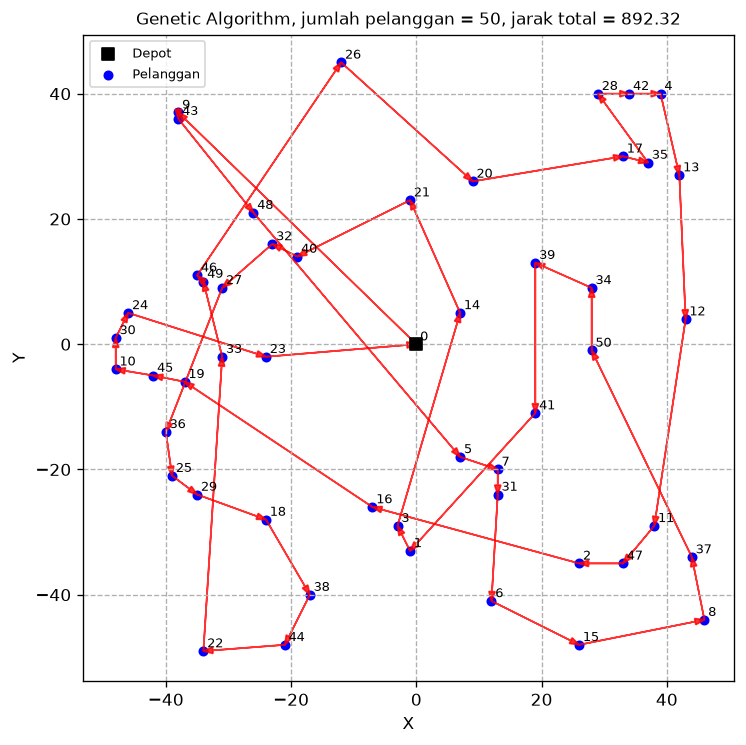

In [3]:
# Genetic Algoritthm untuk TSP

import numpy as np
import random as rd
import matplotlib.pyplot as plt
import time

# Data
np.random.seed(1707) # seed agar data random yang dibangkitkan selalu tetap
jumlah_pelanggan = 50  # dapat diatur jumlah pelanggan
jumlah_simpul = jumlah_pelanggan + 1
# simpul depot pada koordinat (0, 0) dan koordinat simpul pelanggan random (-50, 50)
koord_x = [0] + [np.random.randint(-50, 50) for _ in range(jumlah_simpul - 1)]
koord_y = [0] + [np.random.randint(-50, 50) for _ in range(jumlah_simpul - 1)]

jarak = np.zeros((jumlah_simpul, jumlah_simpul))
# list simpul mulai dari depot (simpul 0) s/d jumlah simpul
daftar_simpul = list(range(jumlah_simpul))
# Hitung jarak Euclides
for i in daftar_simpul:
    for j in daftar_simpul:
        if i != j:
            jarak[i][j] = \
            np.sqrt((koord_x[i] - koord_x[j])**2 + (koord_y[i] - koord_y[j])**2)
np.random.seed(None) # nonaktifkan seed dalam randomisasi


# Parameter-parameter algoritma:
ukuran_populasi = 200
crossover_rate = 0.7
mutation_rate = 0.05
max_generation = 1000

# parameter-paramater masalah:
panjang_kromosom = jumlah_simpul - 1
ukuran_turnamen = int(0.1*ukuran_populasi) # Define ukuran_turnamen

# pembangkitan populasi awal
def pembangkitan_populasi_awal(ukuran_populasi, jumlah_titik, panjang_kromosom):
    populasi = []
    for _ in range(ukuran_populasi):
        simpul_tersedia = daftar_simpul[1:]
        kromosom = rd.sample(simpul_tersedia, jumlah_titik - 1)
        populasi.append(kromosom)

    print(np.array(populasi))
    print()

    return populasi

# proses dekoding, penentuan nilai fungsi tujuan, dan nilai fitnes
def evalusi_populasi(ukuran_populasi, kromosom, panjang_kromosom, jarak):

    # Bangun solusi dari kromosom
    solusi = [[0] * (panjang_kromosom + 2) for _ in range(ukuran_populasi)]
    total_jarak = [0.0] * ukuran_populasi
    fitness = [0.0] * ukuran_populasi
    for p in range(ukuran_populasi):
        solusi[p] = [0] + list(map(int, kromosom[p])) + [0]

    # Hitung total jarak
    for p in range(ukuran_populasi):
        total_jarak[p] = sum(jarak[solusi[p][j]][solusi[p][j + 1]] for j in range(len(solusi[p]) - 1))

    # Hitung fitness
    for p in range(ukuran_populasi):
        # fitness = 1 / jarak total
        fitness[p] = 1 / total_jarak[p] if total_jarak[p] != 0 else 0

    # Cari solusi terbaik pada popuplasi
    p_best = np.argmax(fitness) # maksimisasi fitness (minimisasi jarak total)
    best_solusi = solusi[p_best]
    best_fitness = fitness[p_best]

    return solusi, total_jarak, fitness, p_best


# Seleksi Turnamem
def seleksi_turnamen(ukuran_populasi, x_populasi, nilai_fitness, ukuran_turnamen): # Added ukuran_turnamen as argument
    # membuat list yang berisi indeks calon induk sebanyak ukuran turnamen
    indeks_parent_terpilih = rd.sample(range(ukuran_populasi), ukuran_turnamen)
    kandidat = [(x_populasi[i], nilai_fitness[i]) for i in indeks_parent_terpilih]
    kandidat.sort(key=lambda x: x[1], reverse=True) # urutkan berdasarkan fitness (kasus maksimisasi)
    parent = kandidat[0][0] # pilih pada urutan pertama
    return parent

def position_based_crossover(induk1, induk2): # Removed unnecessary arguments
    panjang_kromosom = len(induk1)
    anak1 = [None] * panjang_kromosom
    anak2 = [None] * panjang_kromosom
    jumlah_posisi_yang_dipilih = np.random.randint(1, panjang_kromosom)
    posisi_yang_dipilih = np.random.choice(panjang_kromosom, jumlah_posisi_yang_dipilih, replace=False)
    posisi_yang_dipilih.sort()
    for posisi in posisi_yang_dipilih:
        anak1[posisi] = induk1[posisi]
    sisa_gen_induk2 = [gen for gen in induk2 if gen not in [anak1[pos] for pos in posisi_yang_dipilih]]
    indeks_sisa_gen = 0
    for i in range(panjang_kromosom):
        if anak1[i] is None:
            anak1[i] = sisa_gen_induk2[indeks_sisa_gen]
            indeks_sisa_gen += 1
    for posisi in posisi_yang_dipilih:
        anak2[posisi] = induk2[posisi]
    sisa_gen_induk1 = [gen for gen in induk1 if gen not in [anak2[pos] for pos in posisi_yang_dipilih]]
    indeks_sisa_gen = 0
    for i in range(panjang_kromosom):
        if anak2[i] is None:
            anak2[i] = sisa_gen_induk1[indeks_sisa_gen]
            indeks_sisa_gen += 1
    return anak1, anak2

def swap_mutation(kromosom): # Removed unnecessary arguments
    panjang_kromosom = len(kromosom)
    idx1 = rd.randint(0,panjang_kromosom-1)
    idx2 = rd.randint(0,panjang_kromosom-1)
    while idx2 == idx1:
        idx2 = rd.randint(0,panjang_kromosom-1)
    kromosom[idx1], kromosom[idx2] = kromosom[idx2], kromosom[idx1]
    return kromosom

# fungsi reproduksi
def reproduksi(ukuran_populasi, populasi, nilai_fitness, crossover_rate, mutation_rate, ukuran_turnamen): # Added ukuran_turnamen as argument

    populasi_lama = populasi.copy()
    populasi_baru  = []

    for _ in range(ukuran_populasi // 2):
        # Seleksi turnamen
        induk1 = seleksi_turnamen(ukuran_populasi, populasi_lama, nilai_fitness, ukuran_turnamen) # Added comma and ukuran_turnamen
        induk2 = seleksi_turnamen(ukuran_populasi, populasi_lama, nilai_fitness, ukuran_turnamen) # Added ukuran_turnamen

        # Persilangan
        if np.random.random() < crossover_rate:
            anak1, anak2 = position_based_crossover(induk1, induk2)
        else:
            anak1, anak2 = induk1.copy(), induk2.copy()

        # Mutasi
        if np.random.random() < mutation_rate:
            anak1 = swap_mutation(anak1) # lakukan mutasi
        if np.random.random() < mutation_rate:
            anak2 = swap_mutation(anak2) # lakukan mutasi

        # Pembaruan populasi
        populasi_baru.append(anak1)
        populasi_baru.append(anak2)

    return populasi_baru

def genetic_algorithm_tsp(jarak, jumlah_simpul, ukuran_populasi, crossover_rate, mutation_rate, max_generation, ukuran_turnamen): # Added ukuran_turnamen as argument
    gen = 0

    populasi = pembangkitan_populasi_awal(ukuran_populasi, jumlah_simpul, panjang_kromosom)
    # Evaluasi populasi
    solusi, total_jarak, fitness, p_best = evalusi_populasi(ukuran_populasi, populasi, panjang_kromosom, jarak)

    # Inisialisasi best solution
    best_idx = np.argmax(fitness)
    best_solusi = solusi[best_idx]
    best_fitness = fitness[best_idx]

    while gen <= max_generation:

        # Reproduksi (seleksi, persilangan, mutasi)
        populasi = reproduksi(ukuran_populasi, populasi, fitness, crossover_rate, mutation_rate, ukuran_turnamen)

        # Evaluasi solusi (dekoding, nilai fungsi tujuan, nilai fitness)
        solusi, total_jarak, fitness, p_best = evalusi_populasi(ukuran_populasi, populasi, panjang_kromosom, jarak)

        # Pembaruan solusi terabaik sepanjang generasi
        idx = np.argmax(fitness)
        if fitness[idx] > best_fitness:
            best_solusi = solusi[idx]
            best_fitness = fitness[idx]

        # Cetak kemajuan solusi terbaik tiap 100 generasi
        if gen % 100 == 0:
            print(f'generasi = {gen+1}, jarak total = {1/best_fitness:.4f}, fitnes = {best_fitness:.6f}')
        gen += 1
    return best_solusi, best_fitness

# Kode utama
saat_mulai = time.time()
best_solusi, best_fitness =  genetic_algorithm_tsp(jarak, jumlah_simpul, ukuran_populasi, crossover_rate, mutation_rate, max_generation, ukuran_turnamen) # Added ukuran_turnamen
waktu_komputasi = time.time() - saat_mulai

print('\nSolusi terbaik:')
best_solusi = [int(i) for i in best_solusi]
print(f'{best_solusi}')
print(f'jarak total = {1/best_fitness:.4f}')
print(f'waktu komputasi = {waktu_komputasi:.2f} detik')

# Visualisasi solusi
solusi = best_solusi
jarak_total = 1/best_fitness
plt.figure(figsize=(7, 7))
plt.scatter(koord_x[0], koord_y[0], marker='s', color='black', s=50, label='Depot', zorder=5)
plt.scatter(koord_x[1:], koord_y[1:], marker='o', color='blue', s=25, label='Pelanggan')
for i in daftar_simpul:
    plt.text(koord_x[i] + 0.6, koord_y[i] + 0.6, str(i), fontsize=8)
for i in range(len(solusi) - 1):
    current_node, next_node = solusi[i], solusi[i + 1]
    plt.arrow(koord_x[current_node], koord_y[current_node],
              koord_x[next_node] - koord_x[current_node],
              koord_y[next_node] - koord_y[current_node],
              head_width=1, length_includes_head=True,
              color='red', alpha=0.8)
plt.title(f"Genetic Algorithm, jumlah pelanggan = {jumlah_pelanggan}, jarak total = {jarak_total:.2f}", fontsize=10)
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True,linestyle='--')
plt.axis("equal")
plt.legend(fontsize=8)
plt.show()

✏️ **Latihan 2.1** — Apakah jarak total yang diperoleh sama dengan hasil mahasiswa lain? Data dibangkitkan dengan seed tetap (1707) sehingga instance-nya identik. Jelaskan sumber perbedaannya.

✏️ **Latihan 2.2** — Berdasarkan cetakan setiap 100 generasi, pada generasi ke berapa laju perbaikan mulai menurun?

## Tahap 3 — Pengukuran sebelum perbaikan

Sebagaimana pada tugas ALNS, sebelum algoritma diubah perlu diidentifikasi terlebih dahulu **fungsi yang paling memakan waktu**. Profiler dijalankan untuk 100 generasi.

In [4]:
import cProfile, pstats

max_generation_uji = 100
profiler = cProfile.Profile()
profiler.enable()
genetic_algorithm_tsp(jarak, jumlah_simpul, ukuran_populasi, crossover_rate,
                      mutation_rate, max_generation_uji, ukuran_turnamen)
profiler.disable()
pstats.Stats(profiler).sort_stats("tottime").print_stats(6)

[[21  2 13 ...  7 40 27]
 [23 28 41 ... 14  2 20]
 [44  1 30 ... 29 47 46]
 ...
 [45 40 48 ... 28 18  6]
 [39  9 26 ... 21 23 10]
 [ 5 32 20 ... 38 42 12]]

generasi = 1, jarak total = 2222.9126, fitnes = 0.000450
generasi = 101, jarak total = 1057.3050, fitnes = 0.000946
         3700915 function calls (3700867 primitive calls) in 3.620 seconds

   Ordered by: internal time
   List reduced from 82 to 6 due to restriction <6>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
     7106    1.904    0.000    1.999    0.000 <cell-7>:87(position_based_crossover)
  1060800    0.310    0.000    0.310    0.000 <cell-7>:63(<genexpr>)
    20400    0.267    0.000    0.750    0.000 C:\Users\User\AppData\Local\Programs\Python\Python313\Lib\random.py:363(sample)
   436675    0.223    0.000    0.343    0.000 C:\Users\User\AppData\Local\Programs\Python\Python313\Lib\random.py:245(_randbelow_with_getrandbits)
    20400    0.195    0.000    0.504    0.000 {built-in method builtins

Pada `position_based_crossover`, baris berikut dieksekusi untuk **setiap gen** induk 2:
```python
sisa_gen_induk2 = [gen for gen in induk2 if gen not in [anak1[pos] for pos in posisi_yang_dipilih]]
```
Daftar `[anak1[pos] ...]` dibangun ulang setiap kali dan ditelusuri secara linear, sehingga untuk 50 gen diperlukan sekitar 50 × 50 operasi per anak. Perbaikannya adalah membangun daftar tersebut **satu kali** sebagai `set`, yang pencariannya berlangsung dalam waktu konstan.

In [5]:
def position_based_crossover_cepat(induk1, induk2):          # BARU, ganti fungsi crossover
    panjang_kromosom = len(induk1)
    jumlah_posisi_yang_dipilih = rd.randint(1, panjang_kromosom - 1)
    posisi_yang_dipilih = rd.sample(range(panjang_kromosom), jumlah_posisi_yang_dipilih)

    def buat_anak(induk_a, induk_b): # Berbentuk set
        anak = [None] * panjang_kromosom
        for posisi in posisi_yang_dipilih:
            anak[posisi] = induk_a[posisi]
        sudah_ada = {induk_a[posisi] for posisi in posisi_yang_dipilih}   # set, dibangun sekali
        sisa_gen = iter([gen for gen in induk_b if gen not in sudah_ada]) # hati-hati nama variabel
        for i in range(panjang_kromosom):
            if anak[i] is None:
                anak[i] = next(sisa_gen)
        return anak

    return buat_anak(induk1, induk2), buat_anak(induk2, induk1)

# uji kebenaran dan kecepatan
import time
induk1 = rd.sample(range(1, jumlah_simpul), jumlah_simpul - 1)
induk2 = rd.sample(range(1, jumlah_simpul), jumlah_simpul - 1)
for nama, fungsi in [("asli", position_based_crossover), ("cepat", position_based_crossover_cepat)]:
    a1, a2 = fungsi(induk1, induk2)
    assert sorted(a1) == sorted(induk1) and sorted(a2) == sorted(induk1), "anak bukan permutasi!"
    mulai = time.time()
    for _ in range(5000):
        fungsi(induk1, induk2)
    print(f"{nama:<6}: {time.time() - mulai:.3f} detik untuk 5000 persilangan")

asli  : 1.477 detik untuk 5000 persilangan
cepat : 0.095 detik untuk 5000 persilangan


✏️ **Latihan 3.1** — Perbaikan kedua: `evalusi_populasi` mengakses `jarak[i][j]` dari array NumPy satu per satu, yang pada Python murni justru lebih lambat. Bandingkan waktu `sum(...)` memakai `jarak` dengan memakai `jarak_list = jarak.tolist()`.

✏️ **Latihan 3.2** — Jelaskan mengapa perbaikan efisiensi ini **tidak mengubah** algoritma. Apa dampaknya apabila dengan waktu yang sama jumlah generasi dapat ditingkatkan?

In [6]:
# Latihan 3.1
jarak_list = jarak.tolist()
rute = [0] + induk1 + [0]
for nama, D in [("numpy", jarak), ("list", jarak_list)]:
    mulai = time.time()
    for _ in range(5000):
        sum(D[rute[j]][rute[j + 1]] for j in range(len(rute) - 1))
    print(f"{nama:<6}: {time.time() - mulai:.3f} detik untuk 5000 evaluasi")

numpy : 0.065 detik untuk 5000 evaluasi
list  : 0.025 detik untuk 5000 evaluasi


## Tahap 4 — Riwayat konvergensi dan elitisme

Kode asli menyimpan solusi terbaik **sepanjang eksekusi** di luar populasi, sedangkan populasi diganti seluruhnya oleh anak, sehingga individu terbaik dapat hilang dari populasi.

`genetic_algorithm_tsp_v2` merupakan penataan ulang fungsi asli dengan tambahan berikut:
- `seed` agar hasil dapat direproduksi;
- `riwayat`: terbaik di populasi, terbaik sepanjang eksekusi, rata-rata populasi;
- `jumlah_elit`: individu terbaik yang langsung disalin ke generasi berikutnya;
- operator crossover dan mutasi dapat diganti (digunakan pada Tahap 5), serta `pemoles` (Tahap 7).

Seleksi turnamen dan swap mutation menggunakan fungsi asli tanpa perubahan.

In [7]:
def jarak_kromosom(kromosom, jarak_list):                           # BARU
    rute = [0] + kromosom + [0]
    return sum(jarak_list[rute[j]][rute[j + 1]] for j in range(len(rute) - 1))

def genetic_algorithm_tsp_v2(jarak, ukuran_populasi=200, crossover_rate=0.7, mutation_rate=0.05,
                             max_generation=300, ukuran_turnamen=20, jumlah_elit=0,
                             crossover=None, mutasi=None, pemoles=None, peluang_poles=0.0,
                             seed=None, cetak_tiap=None):
    crossover = crossover or position_based_crossover_cepat
    mutasi = mutasi or swap_mutation
    rd.seed(seed); np.random.seed(seed)                                # BARU: seed
    saat_mulai = time.time()
    jarak_list = np.asarray(jarak).tolist()
    n = len(jarak_list)

    populasi = [rd.sample(range(1, n), n - 1) for _ in range(ukuran_populasi)]
    total_jarak = [jarak_kromosom(k, jarak_list) for k in populasi]
    fitness = [1 / t for t in total_jarak]
    i_best = int(np.argmin(total_jarak))
    best_kromosom, best_jarak = populasi[i_best][:], total_jarak[i_best]
    riwayat = {"terbaik_populasi": [], "terbaik_sepanjang_run": [], "rata_rata": []}  # BARU

    for gen in range(max_generation):
        # BARU: elitisme - salin individu terbaik apa adanya
        urutan = sorted(range(ukuran_populasi), key=lambda i: total_jarak[i])
        populasi_baru = [populasi[i][:] for i in urutan[:jumlah_elit]]

        while len(populasi_baru) < ukuran_populasi:
            induk1 = seleksi_turnamen(ukuran_populasi, populasi, fitness, ukuran_turnamen)
            induk2 = seleksi_turnamen(ukuran_populasi, populasi, fitness, ukuran_turnamen)
            if rd.random() < crossover_rate:
                anak1, anak2 = crossover(induk1, induk2)
            else:
                anak1, anak2 = induk1.copy(), induk2.copy()
            for anak in (anak1, anak2):
                if rd.random() < mutation_rate:
                    anak = mutasi(anak)
                if pemoles is not None and rd.random() < peluang_poles:     # BARU (Tahap 7)
                    anak = pemoles(anak, jarak_list)
                if len(populasi_baru) < ukuran_populasi:
                    populasi_baru.append(anak)

        populasi = populasi_baru
        total_jarak = [jarak_kromosom(k, jarak_list) for k in populasi]
        fitness = [1 / t for t in total_jarak]
        i_best = int(np.argmin(total_jarak))
        if total_jarak[i_best] < best_jarak:
            best_kromosom, best_jarak = populasi[i_best][:], total_jarak[i_best]

        riwayat["terbaik_populasi"].append(total_jarak[i_best])
        riwayat["terbaik_sepanjang_run"].append(best_jarak)
        riwayat["rata_rata"].append(float(np.mean(total_jarak)))
        if cetak_tiap and gen % cetak_tiap == 0:
            print(f"generasi = {gen + 1}, jarak total terbaik = {best_jarak:.2f}")

    return {"solusi": [0] + best_kromosom + [0], "jarak": best_jarak, "riwayat": riwayat,
            "waktu": time.time() - saat_mulai, "evaluasi": ukuran_populasi * (max_generation + 1)}

def plot_konvergensi(hasil, judul=""):
    r = hasil["riwayat"]
    plt.figure(figsize=(7, 4))
    plt.plot(r["terbaik_sepanjang_run"], label="terbaik sepanjang run")
    plt.plot(r["terbaik_populasi"], label="terbaik di populasi", alpha=0.7)
    plt.plot(r["rata_rata"], label="rata-rata populasi", alpha=0.6)
    plt.xlabel("generasi"); plt.ylabel("jarak total"); plt.title(judul, fontsize=10)
    plt.legend(); plt.grid(True, linestyle="--"); plt.show()

def eksperimen(jarak, konfigurasi, seeds, **tetap):
    tabel = {}
    for nama, parameter in konfigurasi.items():
        hasil = [genetic_algorithm_tsp_v2(jarak, seed=s, **tetap, **parameter) for s in seeds]
        nilai = [h["jarak"] for h in hasil]
        tabel[nama] = nilai
        print(f"{nama:<30} rata {np.mean(nilai):8.2f} | terbaik {min(nilai):8.2f} | "
              f"terburuk {max(nilai):8.2f} | sd {np.std(nilai, ddof=1):6.2f} | "
              f"{np.mean([h['waktu'] for h in hasil]):.1f} s/run")
    return tabel

SEEDS = [1, 2, 3, 4, 5]

jumlah_elit = 0: jarak 909.42, waktu 1.5 detik
jumlah_elit = 2: jarak 951.35, waktu 1.5 detik


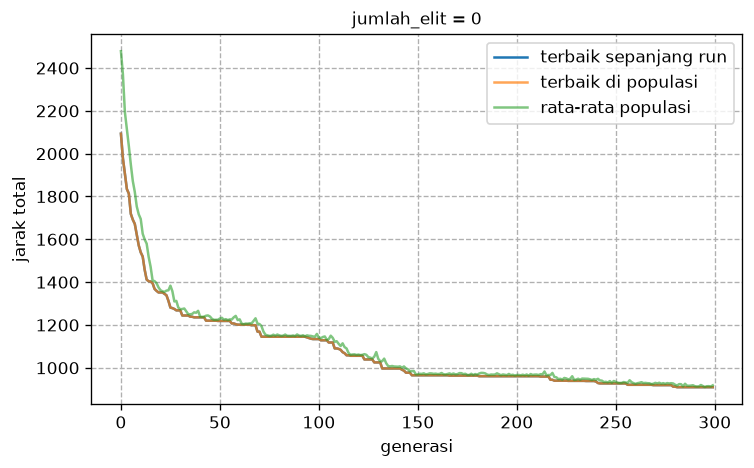

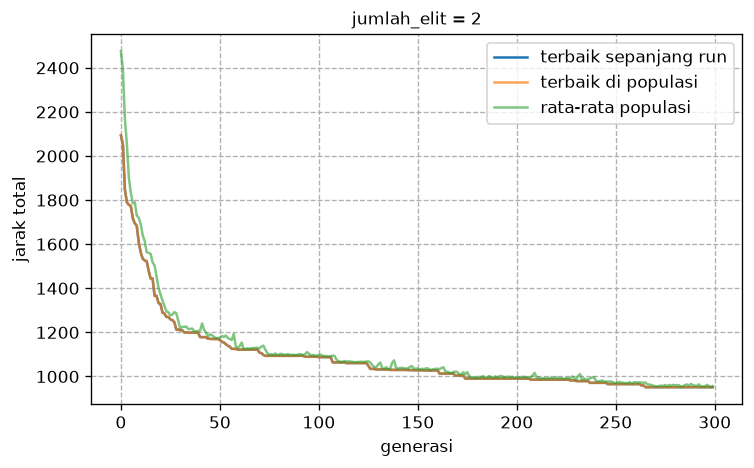

In [8]:
for e in [0, 2]:
    hasil = genetic_algorithm_tsp_v2(jarak, jumlah_elit=e, seed=1)
    print(f"jumlah_elit = {e}: jarak {hasil['jarak']:.2f}, waktu {hasil['waktu']:.1f} detik")
    plot_konvergensi(hasil, f"jumlah_elit = {e}")

✏️ **Latihan 4.1** — Tanpa elitisme, apakah kurva "terbaik di populasi" pernah **naik** (memburuk)? Apa implikasinya terhadap proses pencarian?

✏️ **Latihan 4.2** — Dengan elitisme, kedua kurva terbaik berimpit. Informasi apa yang diberikan oleh selisih antara kurva terbaik dan kurva rata-rata mengenai keragaman populasi?

✏️ **Latihan 4.3** — Pada seed ini, versi dengan elitisme dapat berakhir **lebih buruk**. Apakah dapat disimpulkan bahwa elitisme tidak bermanfaat? Catat dugaan tersebut; fungsi `eksperimen` (beberapa seed sekaligus) digunakan mulai Tahap 5, dan elitisme diuji ulang pada Tahap 6.

## Tahap 5 — Operator lain: OX dan inversion mutation

Pada TSP, panjang rute ditentukan oleh **edge** (pasangan simpul yang bertetangga), bukan oleh posisi gen. Operator yang baik adalah operator yang mewariskan edge.

```
Order crossover OX(induk1, induk2):
1. pilih dua titik potong a <= b
2. anak[a..b] <- induk1[a..b]
3. sisanya diisi gen induk2 mulai dari posisi b+1 (memutar), lewati yang sudah ada

Inversion mutation(k):  pilih i < j, balik urutan k[i..j]     (sama dengan satu langkah 2-opt)
```
Antarmuka disamakan dengan fungsi asli: crossover menghasilkan dua anak, sedangkan mutasi menerima satu kromosom. Diharapkan bisa lebih bagus

In [9]:
def order_crossover(induk1, induk2):                                  # BARU
    panjang_kromosom = len(induk1)
    a, b = sorted(rd.sample(range(panjang_kromosom), 2))

    def buat_anak(induk_a, induk_b):
        anak = [None] * panjang_kromosom
        anak[a:b + 1] = induk_a[a:b + 1]
        sudah_ada = set(induk_a[a:b + 1])
        urutan_b = induk_b[b + 1:] + induk_b[:b + 1]
        sisa_gen = [gen for gen in urutan_b if gen not in sudah_ada]
        posisi_kosong = list(range(b + 1, panjang_kromosom)) + list(range(0, a))
        for posisi, gen in zip(posisi_kosong, sisa_gen):
            anak[posisi] = gen
        return anak

    return buat_anak(induk1, induk2), buat_anak(induk2, induk1)

def inversion_mutation(kromosom):                                     # BARU
    i, j = sorted(rd.sample(range(len(kromosom)), 2))
    kromosom[i:j + 1] = kromosom[i:j + 1][::-1]
    return kromosom

# contoh kecil yang bisa dicek dengan tangan
rd.seed(3)
p1, p2 = [1, 2, 3, 4, 5, 6, 7, 8], [4, 8, 6, 2, 7, 1, 3, 5]
print("induk1:", p1, "\ninduk2:", p2)
print("OX            :", order_crossover(p1, p2))
print("position-based:", position_based_crossover_cepat(p1, p2))

induk1: [1, 2, 3, 4, 5, 6, 7, 8] 
induk2: [4, 8, 6, 2, 7, 1, 3, 5]
OX            : ([6, 2, 7, 4, 5, 1, 3, 8], [3, 4, 5, 2, 7, 6, 8, 1])
position-based: ([1, 6, 3, 4, 5, 2, 7, 8], [4, 1, 6, 2, 7, 3, 8, 5])


Persentase edge anak yang berasal dari salah satu induk diukur pada 2000 pasangan induk acak dengan 50 pelanggan.

In [10]:
def himpunan_edge(kromosom):
    rute = [0] + kromosom
    return {frozenset((rute[i - 1], rute[i])) for i in range(len(rute))}

def persen_edge_warisan(anak, induk1, induk2):
    e = himpunan_edge(anak)
    return 100 * len(e & (himpunan_edge(induk1) | himpunan_edge(induk2))) / len(e)

rd.seed(5)
for nama, cx in [("position-based", position_based_crossover_cepat), ("OX", order_crossover)]:
    nilai = []
    for _ in range(2000):
        i1 = rd.sample(range(1, jumlah_simpul), jumlah_simpul - 1)
        i2 = rd.sample(range(1, jumlah_simpul), jumlah_simpul - 1)
        nilai.append(persen_edge_warisan(cx(i1, i2)[0], i1, i2))
    print(f"{nama:<15}: rata-rata {np.mean(nilai):.1f}% edge anak diwarisi dari induk")

for nama, mut in [("swap", swap_mutation), ("inversion", inversion_mutation)]:
    berubah = []
    for _ in range(2000):
        k = rd.sample(range(1, jumlah_simpul), jumlah_simpul - 1)
        berubah.append(len(himpunan_edge(k) - himpunan_edge(mut(k[:]))))
    print(f"mutasi {nama:<9}: rata-rata {np.mean(berubah):.2f} edge berubah (maks {max(berubah)})")

position-based : rata-rata 62.4% edge anak diwarisi dari induk
OX             : rata-rata 78.2% edge anak diwarisi dari induk
mutasi swap     : rata-rata 3.85 edge berubah (maks 4)
mutasi inversion: rata-rata 2.00 edge berubah (maks 2)


In [11]:
kombinasi = {
    "position-based + swap": (position_based_crossover_cepat, swap_mutation),
    "position-based + inversion": (position_based_crossover_cepat, inversion_mutation),
    "OX + swap": (order_crossover, swap_mutation),
    "OX + inversion": (order_crossover, inversion_mutation),
}
print("Parameter lain sama dengan kode asli (mutation_rate 0.05), elit 2, 5 seed")
t_operator = eksperimen(jarak, {nama: dict(crossover=cx, mutasi=mut) for nama, (cx, mut) in kombinasi.items()},
                        SEEDS, jumlah_elit=2)

Parameter lain sama dengan kode asli (mutation_rate 0.05), elit 2, 5 seed
position-based + swap          rata   963.48 | terbaik   867.16 | terburuk  1046.80 | sd  64.58 | 1.3 s/run
position-based + inversion     rata   649.50 | terbaik   627.14 | terburuk   669.48 | sd  18.82 | 1.7 s/run
OX + swap                      rata   921.32 | terbaik   879.79 | terburuk   991.97 | sd  52.19 | 1.4 s/run
OX + inversion                 rata   649.97 | terbaik   609.56 | terburuk   673.34 | sd  25.56 | 1.5 s/run


✏️ **Latihan 5.1** — Kerjakan OX untuk contoh di atas secara manual. Titik potong dapat ditentukan dari keluaran program.

✏️ **Latihan 5.2** — Kaitkan hasil empat kombinasi dengan persentase edge yang diwariskan dan jumlah edge yang diubah mutasi. Jelaskan mengapa inversion lebih sesuai untuk TSP dibandingkan swap.

✏️ **Latihan 5.3** — Faktor mana yang lebih berpengaruh: pilihan crossover atau pilihan mutasi? Perhatikan pula simpangan baku, tidak hanya rata-rata.

## Tahap 6 — Rancangan eksperimen

Prinsip dari tuning ALNS berlaku pula di sini: satu eksekusi tidak cukup sebagai dasar kesimpulan. Jalankan beberapa seed, kemudian laporkan rata-rata, nilai terbaik, nilai terburuk, dan simpangan baku.

In [12]:
OPERATOR_TERBAIK = dict(crossover=order_crossover, mutasi=inversion_mutation)

print("Laju mutasi (OX + inversion, elit 2)")
t_mutasi = eksperimen(jarak, {f"mutation_rate = {m}": dict(mutation_rate=m) for m in [0.05, 0.2, 0.5]},
                      SEEDS, jumlah_elit=2, **OPERATOR_TERBAIK)

print("\nElitisme (OX + inversion, mutation_rate 0.2)")
t_elit = eksperimen(jarak, {f"jumlah_elit = {e}": dict(jumlah_elit=e) for e in [0, 2, 20]},
                    SEEDS, mutation_rate=0.2, **OPERATOR_TERBAIK)

Laju mutasi (OX + inversion, elit 2)
mutation_rate = 0.05           rata   649.97 | terbaik   609.56 | terburuk   673.34 | sd  25.56 | 1.4 s/run
mutation_rate = 0.2            rata   605.13 | terbaik   593.62 | terburuk   618.32 | sd   9.55 | 1.4 s/run
mutation_rate = 0.5            rata   609.70 | terbaik   589.23 | terburuk   635.99 | sd  17.46 | 1.5 s/run

Elitisme (OX + inversion, mutation_rate 0.2)
jumlah_elit = 0                rata   597.75 | terbaik   572.89 | terburuk   619.61 | sd  20.30 | 1.4 s/run
jumlah_elit = 2                rata   605.13 | terbaik   593.62 | terburuk   618.32 | sd   9.55 | 1.4 s/run
jumlah_elit = 20               rata   599.88 | terbaik   590.11 | terburuk   606.94 | sd   6.63 | 1.2 s/run


✏️ **Latihan 6.1** — Tinjau kembali dugaan pada Latihan 4.3. Elitisme hampir tidak berpengaruh terhadap rata-rata; salah satu penyebabnya adalah turnamen berukuran 20 yang telah memberikan tekanan seleksi besar. Bagaimana pengaruhnya terhadap simpangan baku?

✏️ **Latihan 6.2** — Kode asli memakai `ukuran_turnamen = 10% populasi` (= 20). Uji ukuran 2, 5, dan 20 dengan fungsi `eksperimen`. Jelaskan hubungannya dengan kecepatan konvergensi dan hasil akhir. Ulangi Latihan 6.1 dengan ukuran turnamen 2.

**Anggaran yang setara.** Populasi 400 dengan 300 generasi memperoleh evaluasi dua kali lebih banyak daripada populasi 200. Perbandingan harus dilakukan pada jumlah evaluasi yang sama (ukuran_populasi × max_generation tetap).

In [13]:
# Latihan 6.2: Uji ukuran turnamen 2, 5, dan 20
print("Ukuran turnamen (OX + inversion, elit 2, mutation_rate 0.2)")
t_turnamen = eksperimen(jarak, {f"ukuran_turnamen = {k}": dict(ukuran_turnamen=k) for k in [2, 5, 20]},
                        SEEDS, jumlah_elit=2, mutation_rate=0.2, **OPERATOR_TERBAIK)

Ukuran turnamen (OX + inversion, elit 2, mutation_rate 0.2)
ukuran_turnamen = 2            rata   927.53 | terbaik   818.37 | terburuk   978.42 | sd  64.04 | 0.8 s/run
ukuran_turnamen = 5            rata   611.80 | terbaik   577.86 | terburuk   629.21 | sd  19.84 | 0.9 s/run
ukuran_turnamen = 20           rata   605.13 | terbaik   593.62 | terburuk   618.32 | sd   9.55 | 1.4 s/run


In [14]:
ANGGARAN = 60_000
print(f"Anggaran evaluasi sama: {ANGGARAN}")
t_pop = eksperimen(jarak, {f"populasi {m}, generasi {ANGGARAN // m}":
                           dict(ukuran_populasi=m, max_generation=ANGGARAN // m, ukuran_turnamen=max(2, m // 10))
                           for m in [50, 100, 200, 400]},
                   SEEDS, jumlah_elit=2, mutation_rate=0.2, **OPERATOR_TERBAIK)

Anggaran evaluasi sama: 60000
populasi 50, generasi 1200     rata   616.38 | terbaik   606.17 | terburuk   630.73 | sd  10.17 | 0.9 s/run
populasi 100, generasi 600     rata   602.80 | terbaik   584.50 | terburuk   625.99 | sd  17.38 | 1.0 s/run
populasi 200, generasi 300     rata   605.13 | terbaik   593.62 | terburuk   618.32 | sd   9.55 | 1.4 s/run
populasi 400, generasi 150     rata   613.82 | terbaik   585.66 | terburuk   635.16 | sd  21.11 | 2.1 s/run


✏️ **Latihan 6.3** — Ukuran populasi manakah yang terbaik pada anggaran ini? Jelaskan trade-off antara populasi besar (eksplorasi) dan jumlah generasi besar (eksploitasi).

## Tahap 7 — GA + 2-opt (memetic algorithm)

GA unggul dalam eksplorasi, tetapi lambat dalam memperbaiki rute secara lokal. Local search 2-opt (minggu 3) efektif untuk perbaikan lokal. Pada pendekatan ini, sebagian anak diperbaiki dengan 2-opt sebelum dimasukkan ke populasi.

```
2-opt (first improvement), simpul 0 tetap di depan:
SELAMA ada perbaikan :
   UNTUK setiap pasangan edge (a,b) dan (c,d) :
      delta <- d(a,c) + d(b,d) - d(a,b) - d(c,d)
      JIKA delta < 0 : balik segmen b..c
```

In [15]:
def dua_opt(kromosom, jarak_list):                                    # BARU
    rute = [0] + kromosom
    n = len(rute)
    membaik = True
    while membaik:
        membaik = False
        for i in range(n - 1):
            for j in range(i + 2, n if i > 0 else n - 1):
                a, b = rute[i], rute[i + 1]
                c, d = rute[j], rute[(j + 1) % n]
                delta = jarak_list[a][c] + jarak_list[b][d] - jarak_list[a][b] - jarak_list[c][d]
                if delta < -1e-9:
                    rute[i + 1:j + 1] = rute[i + 1:j + 1][::-1]
                    membaik = True
    return rute[1:]

t_memetic = eksperimen(jarak, {"GA (OX + inversion)": dict(),
                               "GA + 2-opt pada 5% anak": dict(pemoles=dua_opt, peluang_poles=0.05)},
                       SEEDS, jumlah_elit=2, mutation_rate=0.2, **OPERATOR_TERBAIK)

GA (OX + inversion)            rata   605.13 | terbaik   593.62 | terburuk   618.32 | sd   9.55 | 1.4 s/run
GA + 2-opt pada 5% anak        rata   554.14 | terbaik   554.14 | terburuk   554.14 | sd   0.00 | 2.4 s/run


✏️ **Latihan 7.1** — Versi memetic memberikan hasil lebih baik, tetapi setiap pemanggilan 2-opt mengevaluasi ratusan delta sehingga jumlah evaluasi tidak lagi mencerminkan beban komputasi sebenarnya. Bagaimana perbandingan yang adil dapat dilakukan? (Petunjuk: waktu komputasi yang sama.)

✏️ **Latihan 7.2** — Gambarkan kurva konvergensi versi memetic menggunakan `plot_konvergensi`. Bagaimana perubahan selisih antara kurva terbaik dan rata-rata, dan apa risikonya?

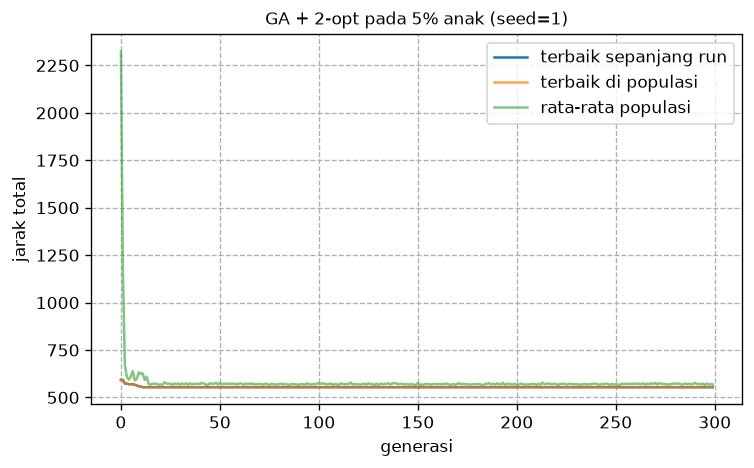

In [16]:
# Latihan 7.2: Kurva konvergensi versi memetic
hasil_memetic_contoh = genetic_algorithm_tsp_v2(
    jarak, jumlah_elit=2, mutation_rate=0.2, pemoles=dua_opt, peluang_poles=0.05, seed=1, **OPERATOR_TERBAIK
)
plot_konvergensi(hasil_memetic_contoh, "GA + 2-opt pada 5% anak (seed=1)")

## Tantangan kelas — satu modifikasi sendiri (20 menit)

Rancang **satu** modifikasi GA, implementasikan, dan uji dengan fungsi `eksperimen` (3 seed, anggaran 60.000 evaluasi). Di akhir sesi, setiap mahasiswa menyampaikan modifikasinya, rata-rata jarak yang diperoleh, dan alasan modifikasi tersebut berhasil atau tidak.

Contoh di bawah adalah mutasi **or-opt**: satu segmen berisi 1–3 simpul dipindahkan ke posisi lain. Saudara boleh mengubah contoh ini atau merancang modifikasi lain, misalnya operator crossover baru atau mutasi gabungan.

Pembanding: OX + inversion, mutation_rate 0.2, elit 2.

In [17]:
def mutasi_saya(kromosom):                                            # BARU: ubah sesuai rancangan Anda
    # contoh: or-opt, pindahkan segmen 1-3 gen ke posisi lain
    panjang_segmen = rd.randint(1, 3)
    i = rd.randrange(0, len(kromosom) - panjang_segmen + 1)
    segmen = kromosom[i:i + panjang_segmen]
    sisa = kromosom[:i] + kromosom[i + panjang_segmen:]
    j = rd.randrange(0, len(sisa) + 1)
    kromosom[:] = sisa[:j] + segmen + sisa[j:]
    return kromosom

t_tantangan = eksperimen(jarak, {"OX + inversion (pembanding)": dict(mutasi=inversion_mutation),
                                 "OX + mutasi_saya": dict(mutasi=mutasi_saya)},
                         [1, 2, 3], jumlah_elit=2, mutation_rate=0.2, crossover=order_crossover)

OX + inversion (pembanding)    rata   599.79 | terbaik   593.62 | terburuk   607.33 | sd   6.96 | 1.3 s/run
OX + mutasi_saya               rata   635.94 | terbaik   597.99 | terburuk   662.92 | sd  33.83 | 1.4 s/run


## Tahap 8 — Instance TSPLIB (persiapan Tugas GA)

Tugas memakai instance **TSPLIB** `eil51`, `berlin52`, dan `kroA100`. Berkas `.tsp` diunduh dari situs TSPLIB dan diletakkan dalam folder yang sama dengan notebook (pada Colab: unggah melalui panel Files). Jarak mengikuti aturan **EUC_2D**, yaitu dibulatkan ke bilangan bulat terdekat, agar dapat dibandingkan dengan nilai optimal. Kota pertama berperan sebagai simpul 0.

| Instance | Kota | Optimal |
|---|---|---|
| eil51 | 51 | 426 |
| berlin52 | 52 | 7542 |
| kroA100 | 100 | 21282 |

In [18]:
import os

def baca_tsplib(path):
    koord = []
    baca = False
    with open(path) as berkas:
        for baris in berkas:
            baris = baris.strip()
            if baris.startswith("NODE_COORD_SECTION"):
                baca = True
                continue
            if baris.startswith("EOF"):
                break
            if baca and baris:
                _, x, y = baris.split()[:3]
                koord.append((float(x), float(y)))
    P = np.array(koord)
    jarak_euc = np.floor(np.sqrt(((P[:, None, :] - P[None, :, :]) ** 2).sum(axis=-1)) + 0.5)
    return koord, jarak_euc

def baca_opt_tour(path):
    rute_opt = []
    baca = False
    with open(path) as berkas:
        for baris in berkas:
            baris = baris.strip()
            if baris.startswith("TOUR_SECTION"):
                baca = True
                continue
            if baris in ("-1", "EOF") or baris.startswith("EOF"):
                break
            if baca and baris:
                for tok in baris.split():
                    val = int(tok)
                    if val == -1:
                        break
                    rute_opt.append(val - 1)  # Indeks 0-based (simpul pertama = 0 / depot)
    return rute_opt

OPTIMAL = {"eil51": 426, "berlin52": 7542, "kroA100": 21282}
print("=== Verifikasi Pembacaan TSPLIB & .opt.tour ===")
for nama, optimal in OPTIMAL.items():
    if not os.path.exists(f"{nama}.tsp"):
        print(f"{nama}.tsp belum ada, dilewati")
        continue
    koord_tsp, jarak_tsp = baca_tsplib(f"{nama}.tsp")
    info_opt = ""
    if os.path.exists(f"{nama}.opt.tour"):
        tur_opt = baca_opt_tour(f"{nama}.opt.tour")
        kromosom_opt = tur_opt[1:]  # Simpul 0 di awal
        jarak_verifikasi = jarak_kromosom(kromosom_opt, jarak_tsp.tolist())
        assert int(jarak_verifikasi) == optimal, f"Jarak opt {jarak_verifikasi} != {optimal}"
        info_opt = f"| verifikasi {nama}.opt.tour = {int(jarak_verifikasi)} (COCOK)"
    hasil = genetic_algorithm_tsp_v2(jarak_tsp, jumlah_elit=2, mutation_rate=0.2, seed=1, **OPERATOR_TERBAIK)
    print(f"{nama:<9} (n={len(koord_tsp):3d}) | jarak GA: {hasil['jarak']:8.0f} | optimal: {optimal:6d} "
          f"| gap: {100 * (hasil['jarak'] - optimal) / optimal:5.1f}% | {hasil['waktu']:.2f} s {info_opt}")

=== Verifikasi Pembacaan TSPLIB & .opt.tour ===
eil51     (n= 51) | jarak GA:      464 | optimal:    426 | gap:   8.9% | 1.47 s 
berlin52  (n= 52) | jarak GA:     8611 | optimal:   7542 | gap:  14.2% | 1.56 s | verifikasi berlin52.opt.tour = 7542 (COCOK)
kroA100   (n=100) | jarak GA:    24821 | optimal:  21282 | gap:  16.6% | 1.90 s | verifikasi kroA100.opt.tour = 21282 (COCOK)


### Ringkasan
- **Pengukuran sebelum perbaikan.** Sebagian besar waktu komputasi kode asli terpusat pada satu baris crossover; penggunaan `set` mempercepatnya beberapa kali lipat tanpa mengubah algoritma.
- Untuk TSP, operator dinilai dari **edge yang diwariskan**. Pada instance ini **mutasi inversion** paling menentukan; OX sedikit lebih baik dan lebih stabil daripada position-based.
- **Elitisme** menjaga individu terbaik tetap di populasi, tetapi pengaruhnya bergantung pada tekanan seleksi; pada kasus ini hampir tidak tampak karena ukuran turnamen sudah besar.
- Bandingkan konfigurasi dengan **beberapa seed** dan **anggaran yang sama**.
- **GA + 2-opt** memberikan hasil yang jauh lebih baik, tetapi perbandingannya harus menggunakan ukuran beban komputasi yang setara.

# Tugas Minggu 12 — Pengembangan & Evaluasi Algoritma Genetika untuk TSP
**TI4006 Algoritma Optimisasi dan Metaheuristik**  
**NIM:** `14423011`

Bagian ini mengembangkan fungsi `genetic_algorithm_tsp_v2` dari materi hands-on Pertemuan 11 dengan tiga modifikasi terstruktur (`use_M1`, `use_M2`, `use_M3`) dan mengujinya secara sistematis pada tiga instance standar **TSPLIB** (`eil51`, `berlin52`, dan `kroA100`).

| Komponen | Deskripsi & Rujukan |
|---|---|
| **Baseline** | Parameter asli hands-on: `ukuran_populasi = 200`, `max_generation = 300` (`60.000` evaluasi), `position_based_crossover_cepat`, `swap_mutation`, `crossover_rate = 0.7`, `mutation_rate = 0.05`, `ukuran_turnamen = 20`, `jumlah_elit = 0`. |
| **M1 (Paket Hands-On)** | *Order Crossover* (OX — Davis, 1985), *Inversion Mutation*, *Elitism* (`jumlah_elit = 2`), serta pemolesan *Memetic 2-Opt* terbatas pada solusi terbaik generasi (Moscato, 1989). |
| **M2 (Di Luar Hands-On #1)** | Inisialisasi 10% populasi awal dengan heuristik *Multi-Start Nearest Neighbor* + penolakan/mutasi ulang anak yang identik (*duplicate rejection*) untuk menjaga keragaman genetik (Talbi, 2009). |
| **M3 (Di Luar Hands-On #2)** | *Adaptive Mutation Rate* berbasis tingkat stagnasi + *Cataclysmic Restart* melalui perturbasi *Double-Bridge Kick* (4-opt non-sekuensial) pada populasi non-elit saat stagnan (Eshelman, 1991 — CHC; Talbi, 2009). |

In [19]:
# Tahap Persiapan: Pencatatan Spesifikasi Lingkungan Komputasi & Verifikasi Dataset TSPLIB
import platform
import sys
import os
import time
import winreg
import pandas as pd
import numpy as np
import random as rd
import matplotlib.pyplot as plt

def info_spesifikasi_komputasi():
    try:
        key = winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r"HARDWARE\DESCRIPTION\System\CentralProcessor\0")
        cpu_name, _ = winreg.QueryValueEx(key, "ProcessorNameString")
    except Exception:
        cpu_name = platform.processor()
    print("=" * 70)
    print("SPESIFIKASI KOMPUTER & LINGKUNGAN EKSEKUSI (NIM: 14423011)")
    print("=" * 70)
    print(f"Sistem Operasi   : {platform.platform()}")
    print(f"Prosesor (CPU)   : {cpu_name} ({os.cpu_count()} logical cores)")
    print(f"Versi Python     : {sys.version.split()[0]} ({sys.version})")
    print(f"Versi NumPy      : {np.__version__}")
    print(f"Versi Pandas     : {pd.__version__}")
    print("=" * 70)

info_spesifikasi_komputasi()

# Memuat seluruh dataset TSPLIB dan memverifikasi jarak tur optimal terhadap .opt.tour
INSTANCE_TSPLIB = {}
KOORD_TSPLIB = {}
OPTIMAL_TSPLIB = {"eil51": 426, "berlin52": 7542, "kroA100": 21282}

print("\nVerifikasi Matriks Jarak EUC_2D (pembulatan ke bilangan bulat terdekat):")
for nama, opt_val in OPTIMAL_TSPLIB.items():
    koord_i, matriks_i = baca_tsplib(f"{nama}.tsp")
    KOORD_TSPLIB[nama] = koord_i
    INSTANCE_TSPLIB[nama] = matriks_i
    pesan_tour = "Tidak ada file .opt.tour"
    if os.path.exists(f"{nama}.opt.tour"):
        tur_opt = baca_opt_tour(f"{nama}.opt.tour")
        jarak_hitung = int(jarak_kromosom(tur_opt[1:], matriks_i.tolist()))
        assert jarak_hitung == opt_val, f"Mismatch pada {nama}: {jarak_hitung} != {opt_val}"
        pesan_tour = f"Terverifikasi dengan {nama}.opt.tour -> Jarak = {jarak_hitung} (Sesuai Optimal = {opt_val})"
    else:
        pesan_tour = f"Referensi TSPLIB Optimal = {opt_val}"
    print(f"  - {nama:<8} : {len(koord_i):3d} simpul (simpul 0 = kota ke-1) | {pesan_tour}")

SPESIFIKASI KOMPUTER & LINGKUNGAN EKSEKUSI (NIM: 14423011)
Sistem Operasi   : Windows-11-10.0.26200-SP0
Prosesor (CPU)   : 12th Gen Intel(R) Core(TM) i9-12900H (20 logical cores)
Versi Python     : 3.13.5 (3.13.5 (tags/v3.13.5:6cb20a2, Jun 11 2025, 16:15:46) [MSC v.1943 64 bit (AMD64)])
Versi NumPy      : 2.5.2
Versi Pandas     : 2.3.3

Verifikasi Matriks Jarak EUC_2D (pembulatan ke bilangan bulat terdekat):
  - eil51    :  51 simpul (simpul 0 = kota ke-1) | Referensi TSPLIB Optimal = 426
  - berlin52 :  52 simpul (simpul 0 = kota ke-1) | Terverifikasi dengan berlin52.opt.tour -> Jarak = 7542 (Sesuai Optimal = 7542)
  - kroA100  : 100 simpul (simpul 0 = kota ke-1) | Terverifikasi dengan kroA100.opt.tour -> Jarak = 21282 (Sesuai Optimal = 21282)


## Integrasi Modifikasi M1, M2, dan M3 pada `genetic_algorithm_tsp_v2`

Fungsi `genetic_algorithm_tsp_v2` diperluas dengan tetap mempertahankan seluruh parameter aslinya serta menambahkan tiga sakelar boolean (`use_M1`, `use_M2`, `use_M3`) dan `batas_waktu` (untuk pengujian *Equal Time Budget*):
1. **`use_M1`** (*Paket Hands-On*): Mengaktifkan `order_crossover` (OX), `inversion_mutation`, elitisme (`jumlah_elit = 2`), dan pemolesan lokal `dua_opt` terbatas (`max_langkah = 30`) pada individu terbaik generasi (Moscato, 1989).
2. **`use_M2`** (*Inisialisasi Nearest Neighbor + Duplicate Rejection*): Menginisialisasi 10% populasi awal menggunakan heuristik *Nearest Neighbor* (`bangun_tur_nearest_neighbor`, terdiri atas 1 tur *greedy* dari depot 0 dan sisanya *randomized multi-start 2-nearest neighbor*) serta menolak/memutasi ulang anak yang identik dengan anggota populasi (`himpunan_unik`) guna mencegah konvergensi dini (Talbi, 2009).
3. **`use_M3`** (*Adaptive Mutation Rate + Cataclysmic Double-Bridge Restart*): Meningkatkan peluang mutasi secara adaptif seiring bertambahnya generasi stagnan (`mr_aktual = min(0.65, mutation_rate * (1 + 1.5 * stagnasi / ambang_stagnasi))`), serta melakukan *Cataclysmic Restart* berupa perturbasi `double_bridge_kick` (4-opt non-sekuensial) pada populasi non-elit ketika solusi terbaik stagnan selama `ambang_stagnasi = 20` generasi berturut-turut (Eshelman, 1991; Talbi, 2009).

In [20]:
# Implementasi Operator Tambahan (M1, M2, M3) dan Integrasi pada genetic_algorithm_tsp_v2

def dua_opt(kromosom, jarak_list, max_langkah=30):                    # M1: Memetic 2-Opt terbatas (first-improvement)
    rute = [0] + kromosom
    n = len(rute)
    langkah = 0
    membaik = True
    while membaik and langkah < max_langkah:
        membaik = False
        langkah += 1
        for i in range(n - 1):
            for j in range(i + 2, n if i > 0 else n - 1):
                a, b = rute[i], rute[i + 1]
                c, d = rute[j], rute[(j + 1) % n]
                delta = jarak_list[a][c] + jarak_list[b][d] - jarak_list[a][b] - jarak_list[c][d]
                if delta < -1e-9:
                    rute[i + 1:j + 1] = rute[i + 1:j + 1][::-1]
                    membaik = True
                    break
            if membaik:
                break
    return rute[1:]

def bangun_tur_nearest_neighbor(jarak_list, simpul_mulai=None, k_terdekat=1):  # M2: Heuristik Nearest Neighbor
    n = len(jarak_list)
    belum_dikunjungi = set(range(1, n))
    kromosom = []
    if simpul_mulai is not None and simpul_mulai in belum_dikunjungi:
        sekarang = simpul_mulai
        kromosom.append(sekarang)
        belum_dikunjungi.remove(sekarang)
    else:
        sekarang = 0
    while belum_dikunjungi:
        if k_terdekat <= 1 or len(belum_dikunjungi) == 1:
            pilih = min(belum_dikunjungi, key=lambda u: jarak_list[sekarang][u])
        else:
            kandidat = sorted(belum_dikunjungi, key=lambda u: jarak_list[sekarang][u])[:k_terdekat]
            pilih = kandidat[0] if rd.random() < 0.80 else rd.choice(kandidat)
        kromosom.append(pilih)
        belum_dikunjungi.remove(pilih)
        sekarang = pilih
    return kromosom

def double_bridge_kick(kromosom):                                     # M3: Perturbasi 4-Opt Double-Bridge Kick
    n = len(kromosom)
    if n < 8:
        return inversion_mutation(kromosom[:])
    p1, p2, p3 = sorted(rd.sample(range(1, n - 1), 3))
    A, B, C, D = kromosom[:p1], kromosom[p1:p2], kromosom[p2:p3], kromosom[p3:]
    return A + D + C + B

def genetic_algorithm_tsp_v2(jarak, ukuran_populasi=200, crossover_rate=0.7, mutation_rate=0.05,
                             max_generation=300, ukuran_turnamen=20, jumlah_elit=0,
                             crossover=None, mutasi=None, pemoles=None, peluang_poles=0.0,
                             use_M1=False, use_M2=False, use_M3=False,
                             proporsi_nn=0.10, ambang_stagnasi=20, batas_waktu=None,
                             seed=None, cetak_tiap=None):
    # Pengaturan operator berdasarkan sakelar M1 atau parameter eksplisit
    if use_M1:
        crossover = crossover or order_crossover
        mutasi = mutasi or inversion_mutation
        if jumlah_elit == 0:
            jumlah_elit = 2
        pemoles_aktif = pemoles or dua_opt
    else:
        crossover = crossover or position_based_crossover_cepat
        mutasi = mutasi or swap_mutation
        pemoles_aktif = pemoles

    rd.seed(seed); np.random.seed(seed)
    saat_mulai = time.time()
    jarak_list = np.asarray(jarak).tolist()
    n = len(jarak_list)

    # Inisialisasi populasi awal (M2: 10% dari Nearest Neighbor, sisanya acak)
    populasi = []
    if use_M2:
        jumlah_nn = max(1, int(proporsi_nn * ukuran_populasi))
        populasi.append(bangun_tur_nearest_neighbor(jarak_list, simpul_mulai=None, k_terdekat=1))
        simpul_awal_acak = rd.sample(range(1, n), min(n - 1, jumlah_nn - 1))
        for s_awal in simpul_awal_acak:
            populasi.append(bangun_tur_nearest_neighbor(jarak_list, simpul_mulai=s_awal, k_terdekat=2))
        while len(populasi) < jumlah_nn:
            populasi.append(bangun_tur_nearest_neighbor(jarak_list, simpul_mulai=None, k_terdekat=3))

    while len(populasi) < ukuran_populasi:
        populasi.append(rd.sample(range(1, n), n - 1))

    total_jarak = [jarak_kromosom(k, jarak_list) for k in populasi]
    fitness = [1 / t for t in total_jarak]
    i_best = int(np.argmin(total_jarak))
    best_kromosom, best_jarak = populasi[i_best][:], total_jarak[i_best]
    riwayat = {"terbaik_populasi": [], "terbaik_sepanjang_run": [], "rata_rata": []}

    stagnasi = 0
    gen = 0
    while True:
        if batas_waktu is not None:
            if (time.time() - saat_mulai) >= batas_waktu:
                break
        else:
            if gen >= max_generation:
                break

        # M3: Adaptive Mutation Rate berbasis tingkat stagnasi
        if use_M3:
            mr_aktual = min(0.65, mutation_rate * (1.0 + 1.5 * stagnasi / float(ambang_stagnasi)))
        else:
            mr_aktual = mutation_rate

        # Elitisme: salin individu terbaik langsung ke generasi baru
        urutan = sorted(range(ukuran_populasi), key=lambda i: total_jarak[i])
        populasi_baru = [populasi[i][:] for i in urutan[:jumlah_elit]]

        # M2: Himpunan kromosom unik untuk mencegah duplikasi individu di populasi
        if use_M2:
            himpunan_unik = {tuple(k) for k in populasi_baru}

        while len(populasi_baru) < ukuran_populasi:
            induk1 = seleksi_turnamen(ukuran_populasi, populasi, fitness, ukuran_turnamen)
            induk2 = seleksi_turnamen(ukuran_populasi, populasi, fitness, ukuran_turnamen)
            if rd.random() < crossover_rate:
                anak1, anak2 = crossover(induk1, induk2)
            else:
                anak1, anak2 = induk1.copy(), induk2.copy()
            for anak in (anak1, anak2):
                if rd.random() < mr_aktual:
                    anak = mutasi(anak)
                if pemoles is not None and peluang_poles > 0.0 and rd.random() < peluang_poles:
                    anak = pemoles(anak, jarak_list)
                # M2: Mutasi ulang anak yang identik dengan anggota populasi baru
                if use_M2:
                    percobaan = 0
                    while tuple(anak) in himpunan_unik and percobaan < 3:
                        anak = mutasi(anak[:])
                        percobaan += 1
                    himpunan_unik.add(tuple(anak))
                if len(populasi_baru) < ukuran_populasi:
                    populasi_baru.append(anak)

        populasi = populasi_baru
        total_jarak = [jarak_kromosom(k, jarak_list) for k in populasi]
        i_best = int(np.argmin(total_jarak))

        # M1: Pemolesan Memetic 2-Opt terbatas pada solusi terbaik generasi (Moscato, 1989)
        if use_M1 and pemoles_aktif is not None:
            k_poles = pemoles_aktif(populasi[i_best][:], jarak_list)
            d_poles = jarak_kromosom(k_poles, jarak_list)
            if d_poles < total_jarak[i_best]:
                populasi[i_best] = k_poles
                total_jarak[i_best] = d_poles
            if use_M2:
                urutan_gen = sorted(range(ukuran_populasi), key=lambda i: total_jarak[i])
                for idx_kand in urutan_gen[1:6]:
                    if total_jarak[idx_kand] > total_jarak[i_best]:
                        k_p2 = pemoles_aktif(populasi[idx_kand][:], jarak_list)
                        d_p2 = jarak_kromosom(k_p2, jarak_list)
                        if d_p2 < total_jarak[idx_kand]:
                            populasi[idx_kand] = k_p2
                            total_jarak[idx_kand] = d_p2
                        break

        fitness = [1 / t for t in total_jarak]
        i_best = int(np.argmin(total_jarak))
        if total_jarak[i_best] < best_jarak:
            best_kromosom, best_jarak = populasi[i_best][:], total_jarak[i_best]
            stagnasi = 0
        else:
            stagnasi += 1

        # M3: Cataclysmic Restart dengan Double-Bridge Kick saat solusi terbaik stagnan
        if use_M3 and stagnasi >= ambang_stagnasi:
            urutan_kini = sorted(range(ukuran_populasi), key=lambda i: total_jarak[i])
            batas_elit = max(2, jumlah_elit)
            poles_hitung = 0
            for idx_non_elit in urutan_kini[batas_elit:]:
                if rd.random() < 0.60:
                    k_kick = double_bridge_kick(best_kromosom[:])
                    if use_M1 and pemoles_aktif is not None and poles_hitung < 6:
                        k_kick = pemoles_aktif(k_kick, jarak_list)
                        poles_hitung += 1
                    populasi[idx_non_elit] = k_kick
                    total_jarak[idx_non_elit] = jarak_kromosom(k_kick, jarak_list)
            fitness = [1 / t for t in total_jarak]
            i_best = int(np.argmin(total_jarak))
            if total_jarak[i_best] < best_jarak:
                best_kromosom, best_jarak = populasi[i_best][:], total_jarak[i_best]
            stagnasi = 0

        riwayat["terbaik_populasi"].append(total_jarak[i_best])
        riwayat["terbaik_sepanjang_run"].append(best_jarak)
        riwayat["rata_rata"].append(float(np.mean(total_jarak)))
        if cetak_tiap and gen % cetak_tiap == 0:
            print(f"generasi = {gen + 1}, jarak total terbaik = {best_jarak:.2f}")
        gen += 1

    return {"solusi": [0] + best_kromosom + [0], "jarak": best_jarak, "riwayat": riwayat,
            "waktu": time.time() - saat_mulai, "evaluasi": ukuran_populasi * gen, "generasi": gen}

print("Fungsi genetic_algorithm_tsp_v2 dengan sakelar use_M1, use_M2, use_M3 siap digunakan.")

Fungsi genetic_algorithm_tsp_v2 dengan sakelar use_M1, use_M2, use_M3 siap digunakan.


## Langkah 1 — Eksperimen Konfigurasi Baseline
Konfigurasi **Baseline** dijalankan pada ketiga instance TSPLIB (`eil51`, `berlin52`, dan `kroA100`) menggunakan **5 seed tetap** (`[42, 101, 202, 303, 404]`) dengan parameter persis seperti default hands-on:
- `ukuran_populasi = 200`, `max_generation = 300` (**60.000 evaluasi**);
- `crossover = position_based_crossover_cepat` (`crossover_rate = 0.7`);
- `mutasi = swap_mutation` (`mutation_rate = 0.05`);
- `ukuran_turnamen = 20`, `jumlah_elit = 0`, `use_M1 = False`, `use_M2 = False`, `use_M3 = False`.

In [21]:
# Langkah 1: Eksekusi Baseline pada eil51, berlin52, dan kroA100 (5 Seed)
SEEDS_UTAMA = [42, 101, 202, 303, 404]
REKAMAN_CSV = []  # Menyimpan seluruh baris untuk AOM_GA_Hasil_14423011.csv
HASIL_BASELINE = {}

print("=" * 88)
print(f"{'Instance':<10} | {'Terbaik':>8} | {'Rata-rata':>10} | {'Terburuk':>8} | {'SD':>8} | {'Gap Best%':>9} | {'Gap Mean%':>9} | {'Waktu (s)':>9}")
print("-" * 88)

for nama_inst, D_mat in INSTANCE_TSPLIB.items():
    opt_val = OPTIMAL_TSPLIB[nama_inst]
    run_list = []
    for s in SEEDS_UTAMA:
        h = genetic_algorithm_tsp_v2(
            D_mat, ukuran_populasi=200, max_generation=300,
            crossover_rate=0.7, mutation_rate=0.05, ukuran_turnamen=20, jumlah_elit=0,
            use_M1=False, use_M2=False, use_M3=False, seed=s
        )
        run_list.append(h)
        REKAMAN_CSV.append({
            "instance": nama_inst,
            "seed": s,
            "konfigurasi": "Baseline",
            "jarak": int(round(h["jarak"])),
            "waktu": round(h["waktu"], 4)
        })
    HASIL_BASELINE[nama_inst] = run_list
    nilai_j = [r["jarak"] for r in run_list]
    waktu_j = [r["waktu"] for r in run_list]
    gap_best = 100.0 * (min(nilai_j) - opt_val) / opt_val
    gap_mean = 100.0 * (np.mean(nilai_j) - opt_val) / opt_val
    print(f"{nama_inst:<10} | {min(nilai_j):8.0f} | {np.mean(nilai_j):10.2f} | {max(nilai_j):8.0f} | "
          f"{np.std(nilai_j, ddof=1):8.2f} | {gap_best:8.2f}% | {gap_mean:8.2f}% | {np.mean(waktu_j):8.2f}s")
print("=" * 88)

Instance   |  Terbaik |  Rata-rata | Terburuk |       SD | Gap Best% | Gap Mean% | Waktu (s)
----------------------------------------------------------------------------------------
eil51      |      548 |     601.00 |      635 |    32.73 |    28.64% |    41.08% |     1.35s
berlin52   |    10591 |   11262.00 |    11770 |   474.13 |    40.43% |    49.32% |     1.45s
kroA100    |    59295 |   61988.60 |    64677 |  2333.32 |   178.62% |   191.27% |     2.17s


## Langkah 5 — Parameter Tuning (Grid Search pada `eil51`)
Sebelum menjalankan studi ablasi dan evaluasi akhir, dilakukan **Grid Search** pada instance `eil51` untuk menentukan kombinasi parameter terbaik bagi konfigurasi `Lengkap (M1+M2+M3)`:
- Parameter yang diuji ($3 \times 3 = 9$ kombinasi):
  - `mutation_rate` $\in \{0.05, 0.15, 0.30\}$
  - `ukuran_turnamen` $\in \{3, 5, 10\}$
- Menggunakan **3 seed tuning terpisah** (`[11, 22, 33]`) agar tidak terjadi *data leakage* terhadap seed pengujian utama (`[42, 101, 202, 303, 404]`), dengan total **27 eksekusi** (masing-masing 60.000 evaluasi).

HASIL GRID SEARCH PARAMETER TUNING PADA EIL51 (Optimal = 426, Seeds = [11, 22, 33])
Konfigurasi Tuning       |    mr | k_turn |  Terbaik |  Rata-rata | Terburuk |     SD |   Waktu
----------------------------------------------------------------------------------------
Tuning_mr0.05_k3         |  0.05 |      3 |      428 |     429.67 |      431 |   1.53 |   1.31s
Tuning_mr0.05_k5         |  0.05 |      5 |      429 |     430.33 |      431 |   1.15 |   1.48s
Tuning_mr0.05_k10        |  0.05 |     10 |      429 |     430.67 |      432 |   1.53 |   1.64s
Tuning_mr0.15_k3         |  0.15 |      3 |      428 |     429.00 |      430 |   1.00 |   1.37s
Tuning_mr0.15_k5         |  0.15 |      5 |      430 |     430.33 |      431 |   0.58 |   1.78s
Tuning_mr0.15_k10        |  0.15 |     10 |      428 |     429.67 |      431 |   1.53 |   2.85s
Tuning_mr0.30_k3         |  0.30 |      3 |      427 |     429.00 |      432 |   2.65 |   1.86s
Tuning_mr0.30_k5         |  0.30 |      5 |      429 |     

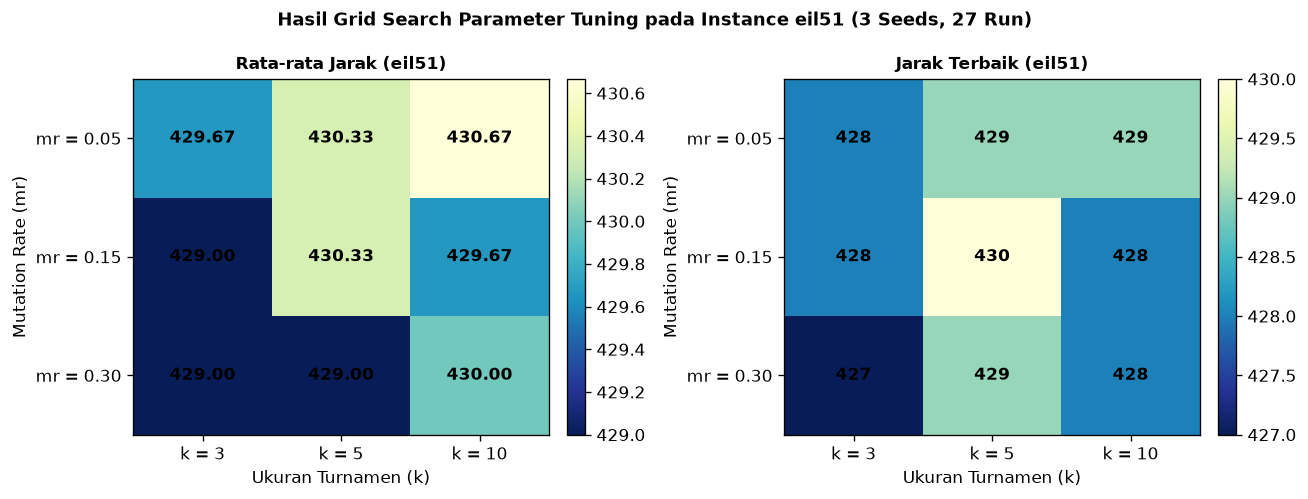

In [22]:
# Langkah 5: Grid Search Parameter Tuning pada eil51 (3 Seed Terpisah: 11, 22, 33 -> 27 Eksekusi)
SEEDS_TUNING = [11, 22, 33]
KANDIDAT_MR = [0.05, 0.15, 0.30]
KANDIDAT_KT = [3, 5, 10]

ringkasan_tuning = []
D_eil51 = INSTANCE_TSPLIB["eil51"]
opt_eil51 = OPTIMAL_TSPLIB["eil51"]

print("=" * 88)
print("HASIL GRID SEARCH PARAMETER TUNING PADA EIL51 (Optimal = 426, Seeds = [11, 22, 33])")
print("=" * 88)
print(f"{'Konfigurasi Tuning':<24} | {'mr':>5} | {'k_turn':>6} | {'Terbaik':>8} | {'Rata-rata':>10} | {'Terburuk':>8} | {'SD':>6} | {'Waktu':>7}")
print("-" * 88)

for mr in KANDIDAT_MR:
    for kt in KANDIDAT_KT:
        label_cfg = f"Tuning_mr{mr:.2f}_k{kt}"
        runs_t = []
        for s in SEEDS_TUNING:
            h = genetic_algorithm_tsp_v2(
                D_eil51, ukuran_populasi=200, max_generation=300,
                crossover_rate=0.7, mutation_rate=mr, ukuran_turnamen=kt, jumlah_elit=2,
                use_M1=True, use_M2=True, use_M3=True, seed=s
            )
            runs_t.append(h)
            REKAMAN_CSV.append({
                "instance": "eil51",
                "seed": s,
                "konfigurasi": label_cfg,
                "jarak": int(round(h["jarak"])),
                "waktu": round(h["waktu"], 4)
            })
        vals = [r["jarak"] for r in runs_t]
        wks = [r["waktu"] for r in runs_t]
        ringkasan_tuning.append({
            "konfigurasi": label_cfg,
            "mutation_rate": mr,
            "ukuran_turnamen": kt,
            "terbaik": min(vals),
            "rata_rata": float(np.mean(vals)),
            "terburuk": max(vals),
            "sd": float(np.std(vals, ddof=1)),
            "waktu": float(np.mean(wks))
        })
        print(f"{label_cfg:<24} | {mr:5.2f} | {kt:6d} | {min(vals):8.0f} | {np.mean(vals):10.2f} | "
              f"{max(vals):8.0f} | {np.std(vals, ddof=1):6.2f} | {np.mean(wks):6.2f}s")

df_tuning = pd.DataFrame(ringkasan_tuning)
df_tuning_urut = df_tuning.sort_values(by=["rata_rata", "terbaik", "sd"]).reset_index(drop=True)
terbaik_row = df_tuning_urut.iloc[0]
MR_TERBAIK = float(terbaik_row["mutation_rate"])
KT_TERBAIK = int(terbaik_row["ukuran_turnamen"])

print("-" * 88)
print(f"Kombinasi Parameter Terbaik: mutation_rate = {MR_TERBAIK}, ukuran_turnamen = {KT_TERBAIK} "
      f"(Rata-rata = {terbaik_row['rata_rata']:.2f}, Terbaik = {terbaik_row['terbaik']:.0f})")
print("=" * 88)

# Visualisasi Heatmap Hasil Parameter Tuning pada eil51
piv_mean = df_tuning.pivot(index="mutation_rate", columns="ukuran_turnamen", values="rata_rata")
piv_best = df_tuning.pivot(index="mutation_rate", columns="ukuran_turnamen", values="terbaik")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, piv, judul, fmt in [
    (axes[0], piv_mean, "Rata-rata Jarak (eil51)", ".2f"),
    (axes[1], piv_best, "Jarak Terbaik (eil51)", ".0f")
]:
    im = ax.imshow(piv.values, cmap="YlGnBu_r", aspect="auto")
    ax.set_xticks(range(len(piv.columns)))
    ax.set_xticklabels([f"k = {c}" for c in piv.columns])
    ax.set_yticks(range(len(piv.index)))
    ax.set_yticklabels([f"mr = {r:.2f}" for r in piv.index])
    ax.set_xlabel("Ukuran Turnamen (k)")
    ax.set_ylabel("Mutation Rate (mr)")
    ax.set_title(judul, fontweight="bold", fontsize=10)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            val = piv.values[i, j]
            ax.text(j, i, f"{val:{fmt}}", ha="center", va="center", color="black", fontweight="bold")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle("Hasil Grid Search Parameter Tuning pada Instance eil51 (3 Seeds, 27 Run)", fontweight="bold", fontsize=11)
plt.tight_layout()
plt.savefig(r"C:\Users\User\.gemini\antigravity\brain\e2aec067-fb97-4e28-819b-5564ad3cc3b1\scratch\fig_tuning_heatmap.png", dpi=220)
plt.show()

## Langkah 4 — Studi Ablasi pada `kroA100` & Evaluasi Konfigurasi `Lengkap` pada Seluruh Instance
Menggunakan parameter hasil tuning (`mutation_rate = 0.30`, `ukuran_turnamen = 3`) dan **5 seed utama** (`[42, 101, 202, 303, 404]`, anggaran **60.000 evaluasi**):
1. **Studi Ablasi pada `kroA100`**: Membandingkan `Lengkap (M1+M2+M3)`, `Tanpa M1` (`M2+M3`), `Tanpa M2` (`M1+M3`), dan `Tanpa M3` (`M1+M2`) untuk mengukur kontribusi marginal tiap modifikasi.
2. **Evaluasi Lintas Instance**: Menjalankan konfigurasi `Lengkap (M1+M2+M3)` pada `eil51` dan `berlin52` (5 seed).

In [23]:
# Langkah 4: Studi Ablasi pada kroA100 & Evaluasi Konfigurasi Lengkap pada eil51 dan berlin52 (5 Seed)
KONFIG_ABLASI = {
    "Lengkap (M1+M2+M3)": dict(use_M1=True,  use_M2=True,  use_M3=True),
    "Tanpa M1":           dict(use_M1=False, use_M2=True,  use_M3=True),
    "Tanpa M2":           dict(use_M1=True,  use_M2=False, use_M3=True),
    "Tanpa M3":           dict(use_M1=True,  use_M2=True,  use_M3=False),
}

HASIL_ABLASI_KRO = {}
D_kro = INSTANCE_TSPLIB["kroA100"]
opt_kro = OPTIMAL_TSPLIB["kroA100"]

print("=" * 95)
print(f"HASIL STUDI ABLASI PADA KROA100 (Optimal = {opt_kro}, mr = {MR_TERBAIK}, ukuran_turnamen = {KT_TERBAIK}, 5 Seeds)")
print("=" * 95)
print(f"{'Konfigurasi':<22} | {'Terbaik':>8} | {'Rata-rata':>10} | {'Terburuk':>8} | {'SD':>8} | {'Gap Best%':>9} | {'Gap Mean%':>9} | {'Waktu':>7}")
print("-" * 95)

for nama_cfg, sakelar in KONFIG_ABLASI.items():
    runs_cfg = []
    for s in SEEDS_UTAMA:
        h = genetic_algorithm_tsp_v2(
            D_kro, ukuran_populasi=200, max_generation=300,
            crossover_rate=0.7, mutation_rate=MR_TERBAIK, ukuran_turnamen=KT_TERBAIK,
            seed=s, **sakelar
        )
        runs_cfg.append(h)
        REKAMAN_CSV.append({
            "instance": "kroA100",
            "seed": s,
            "konfigurasi": nama_cfg,
            "jarak": int(round(h["jarak"])),
            "waktu": round(h["waktu"], 4)
        })
    HASIL_ABLASI_KRO[nama_cfg] = runs_cfg
    vals = [r["jarak"] for r in runs_cfg]
    wks = [r["waktu"] for r in runs_cfg]
    gap_b = 100.0 * (min(vals) - opt_kro) / opt_kro
    gap_m = 100.0 * (np.mean(vals) - opt_kro) / opt_kro
    print(f"{nama_cfg:<22} | {min(vals):8.0f} | {np.mean(vals):10.2f} | {max(vals):8.0f} | "
          f"{np.std(vals, ddof=1):8.2f} | {gap_b:8.2f}% | {gap_m:8.2f}% | {np.mean(wks):6.2f}s")
print("=" * 95)

# Jalankan konfigurasi Lengkap (M1+M2+M3) pada eil51 dan berlin52 (5 Seed)
HASIL_LENGKAP = {"kroA100": HASIL_ABLASI_KRO["Lengkap (M1+M2+M3)"]}

print("\nEvaluasi Konfigurasi Lengkap (M1+M2+M3) pada eil51 dan berlin52 (5 Seeds):")
for nama_inst in ["eil51", "berlin52"]:
    D_mat = INSTANCE_TSPLIB[nama_inst]
    opt_val = OPTIMAL_TSPLIB[nama_inst]
    runs_l = []
    for s in SEEDS_UTAMA:
        h = genetic_algorithm_tsp_v2(
            D_mat, ukuran_populasi=200, max_generation=300,
            crossover_rate=0.7, mutation_rate=MR_TERBAIK, ukuran_turnamen=KT_TERBAIK,
            use_M1=True, use_M2=True, use_M3=True, seed=s
        )
        runs_l.append(h)
        REKAMAN_CSV.append({
            "instance": nama_inst,
            "seed": s,
            "konfigurasi": "Lengkap (M1+M2+M3)",
            "jarak": int(round(h["jarak"])),
            "waktu": round(h["waktu"], 4)
        })
    HASIL_LENGKAP[nama_inst] = runs_l
    vals = [r["jarak"] for r in runs_l]
    wks = [r["waktu"] for r in runs_l]
    gap_b = 100.0 * (min(vals) - opt_val) / opt_val
    gap_m = 100.0 * (np.mean(vals) - opt_val) / opt_val
    print(f"  - {nama_inst:<10} : Terbaik = {min(vals):6.0f} | Rata-rata = {np.mean(vals):8.2f} | "
          f"Terburuk = {max(vals):6.0f} | SD = {np.std(vals, ddof=1):6.2f} | Gap Best = {gap_b:5.2f}% | "
          f"Gap Mean = {gap_m:5.2f}% | Waktu = {np.mean(wks):.2f}s")

HASIL STUDI ABLASI PADA KROA100 (Optimal = 21282, mr = 0.3, ukuran_turnamen = 3, 5 Seeds)
Konfigurasi            |  Terbaik |  Rata-rata | Terburuk |       SD | Gap Best% | Gap Mean% |   Waktu
-----------------------------------------------------------------------------------------------
Lengkap (M1+M2+M3)     |    21282 |   21364.00 |    21446 |    80.82 |     0.00% |     0.39% |   2.65s
Tanpa M1               |    26605 |   27160.00 |    27484 |   416.24 |    25.01% |    27.62% |   1.50s
Tanpa M2               |    21282 |   21485.00 |    21735 |   163.53 |     0.00% |     0.95% |   2.28s
Tanpa M3               |    21634 |   21994.20 |    22252 |   252.65 |     1.65% |     3.35% |   1.81s

Evaluasi Konfigurasi Lengkap (M1+M2+M3) pada eil51 dan berlin52 (5 Seeds):
  - eil51      : Terbaik =    428 | Rata-rata =   429.60 | Terburuk =    431 | SD =   1.52 | Gap Best =  0.47% | Gap Mean =  0.85% | Waktu = 1.11s
  - berlin52   : Terbaik =   7542 | Rata-rata =  7542.00 | Terburuk =   7542

## Langkah 3 — Eksperimen Equal Time Budget (`Baseline_EqualTime` pada `kroA100`)
Karena konfigurasi `Lengkap (M1+M2+M3)` menggunakan pemolesan lokal 2-Opt yang menambah waktu komputasi per generasi, perbandingan yang adil (*fair comparison*) dilakukan dengan menjalankan konfigurasi **Baseline** pada `kroA100` tanpa batas generasi (`batas_waktu` disamakan dengan rata-rata waktu komputasi `Lengkap` pada `kroA100`) untuk ke-5 seed utama.

In [24]:
# Langkah 3: Eksekusi Baseline_EqualTime pada kroA100 (5 Seed)
waktu_target_kro = float(np.mean([r["waktu"] for r in HASIL_LENGKAP["kroA100"]]))
print(f"Rata-rata waktu komputasi Lengkap (M1+M2+M3) pada kroA100 = {waktu_target_kro:.2f} detik/run")
print(f"Menjalankan Baseline_EqualTime pada kroA100 dengan batas_waktu = {waktu_target_kro:.2f} detik...")

HASIL_EQUAL_TIME = []
for s in SEEDS_UTAMA:
    h_eq = genetic_algorithm_tsp_v2(
        D_kro, ukuran_populasi=200, max_generation=100_000,
        crossover_rate=0.7, mutation_rate=0.05, ukuran_turnamen=20, jumlah_elit=0,
        use_M1=False, use_M2=False, use_M3=False, batas_waktu=waktu_target_kro, seed=s
    )
    HASIL_EQUAL_TIME.append(h_eq)
    REKAMAN_CSV.append({
        "instance": "kroA100",
        "seed": s,
        "konfigurasi": "Baseline_EqualTime",
        "jarak": int(round(h_eq["jarak"])),
        "waktu": round(h_eq["waktu"], 4)
    })

vals_eq = [r["jarak"] for r in HASIL_EQUAL_TIME]
gen_eq = [r["generasi"] for r in HASIL_EQUAL_TIME]
eval_eq = [r["evaluasi"] for r in HASIL_EQUAL_TIME]
wks_eq = [r["waktu"] for r in HASIL_EQUAL_TIME]

print("=" * 95)
print("PERBANDINGAN ADIL (EQUAL TIME BUDGET) PADA KROA100 (5 Seeds)")
print("=" * 95)
for label_p, list_p in [
    ("Baseline (60k eval)", HASIL_BASELINE["kroA100"]),
    ("Baseline_EqualTime", HASIL_EQUAL_TIME),
    ("Lengkap (M1+M2+M3)", HASIL_LENGKAP["kroA100"]),
]:
    v = [r["jarak"] for r in list_p]
    w = [r["waktu"] for r in list_p]
    ev = [r["evaluasi"] for r in list_p]
    print(f"{label_p:<22} | Terbaik: {min(v):6.0f} | Rata-rata: {np.mean(v):9.2f} | Terburuk: {max(v):6.0f} | "
          f"SD: {np.std(v, ddof=1):7.2f} | Gap Mean: {100*(np.mean(v)-opt_kro)/opt_kro:6.2f}% | "
          f"Rata Evaluasi: {np.mean(ev):9.0f} | Waktu: {np.mean(w):.2f}s")
print("=" * 95)

Rata-rata waktu komputasi Lengkap (M1+M2+M3) pada kroA100 = 2.65 detik/run
Menjalankan Baseline_EqualTime pada kroA100 dengan batas_waktu = 2.65 detik...
PERBANDINGAN ADIL (EQUAL TIME BUDGET) PADA KROA100 (5 Seeds)
Baseline (60k eval)    | Terbaik:  59295 | Rata-rata:  61988.60 | Terburuk:  64677 | SD: 2333.32 | Gap Mean: 191.27% | Rata Evaluasi:     60000 | Waktu: 2.17s
Baseline_EqualTime     | Terbaik:  56179 | Rata-rata:  59024.00 | Terburuk:  61108 | SD: 2132.52 | Gap Mean: 177.34% | Rata Evaluasi:     83480 | Waktu: 2.65s
Lengkap (M1+M2+M3)     | Terbaik:  21282 | Rata-rata:  21364.00 | Terburuk:  21446 | SD:   80.82 | Gap Mean:   0.39% | Rata Evaluasi:     60000 | Waktu: 2.65s


## Rekapitulasi Tabel Utama, Ekspor CSV, dan Visualisasi Konvergensi & Rute Terbaik
Seluruh hasil eksperimen disimpan ke dalam berkas **`AOM_GA_Hasil_14423011.csv`** dengan kolom wajib `instance,seed,konfigurasi,jarak,waktu`.

In [25]:
# Simpan CSV Luaran Wajib: AOM_GA_Hasil_14423011.csv
df_hasil_csv = pd.DataFrame(REKAMAN_CSV)[["instance", "seed", "konfigurasi", "jarak", "waktu"]]
csv_path = "AOM_GA_Hasil_14423011.csv"
df_hasil_csv.to_csv(csv_path, index=False)
print(f"Berkas '{csv_path}' berhasil disimpan ({len(df_hasil_csv)} baris eksekusi).")
print("\n10 Baris Pertama AOM_GA_Hasil_14423011.csv:")
print(df_hasil_csv.head(10).to_string(index=False))

# Tabel Utama Perbandingan Baseline vs Konfigurasi Terbaik (Lengkap) pada 3 Instance
baris_tabel_utama = []
for nama_inst in ["eil51", "berlin52", "kroA100"]:
    opt_v = OPTIMAL_TSPLIB[nama_inst]
    for nama_konf, sumber in [
        ("Baseline", HASIL_BASELINE[nama_inst]),
        ("Lengkap (M1+M2+M3)", HASIL_LENGKAP[nama_inst])
    ]:
        arr_j = [r["jarak"] for r in sumber]
        arr_w = [r["waktu"] for r in sumber]
        baris_tabel_utama.append({
            "Instance": nama_inst,
            "Optimal": opt_v,
            "Konfigurasi": nama_konf,
            "Terbaik": int(min(arr_j)),
            "Rata-rata": round(float(np.mean(arr_j)), 2),
            "Terburuk": int(max(arr_j)),
            "Simpangan Baku": round(float(np.std(arr_j, ddof=1)), 2),
            "Gap Terbaik (%)": round(100.0 * (min(arr_j) - opt_v) / opt_v, 2),
            "Gap Rata-rata (%)": round(100.0 * (np.mean(arr_j) - opt_v) / opt_v, 2),
            "Waktu Rata-rata (s)": round(float(np.mean(arr_w)), 2)
        })

df_utama = pd.DataFrame(baris_tabel_utama)
print("\n" + "=" * 112)
print("TABEL UTAMA PERBANDINGAN BASELINE VS KONFIGURASI TERBAIK (LENGKAP M1+M2+M3) PADA 3 INSTANCE TSPLIB (5 SEEDS)")
print("=" * 112)
print(df_utama.to_string(index=False))
print("=" * 112)

Berkas 'AOM_GA_Hasil_14423011.csv' berhasil disimpan (77 baris eksekusi).

10 Baris Pertama AOM_GA_Hasil_14423011.csv:
instance  seed konfigurasi  jarak  waktu
   eil51    42    Baseline    617 1.2719
   eil51   101    Baseline    597 1.5096
   eil51   202    Baseline    635 1.3437
   eil51   303    Baseline    608 1.3394
   eil51   404    Baseline    548 1.3049
berlin52    42    Baseline  10591 1.4907
berlin52   101    Baseline  11770 1.3142
berlin52   202    Baseline  11539 1.3405
berlin52   303    Baseline  11437 1.4335
berlin52   404    Baseline  10973 1.6655

TABEL UTAMA PERBANDINGAN BASELINE VS KONFIGURASI TERBAIK (LENGKAP M1+M2+M3) PADA 3 INSTANCE TSPLIB (5 SEEDS)
Instance  Optimal        Konfigurasi  Terbaik  Rata-rata  Terburuk  Simpangan Baku  Gap Terbaik (%)  Gap Rata-rata (%)  Waktu Rata-rata (s)
   eil51      426           Baseline      548      601.0       635           32.73            28.64              41.08                 1.35
   eil51      426 Lengkap (M1+M2+M3)    

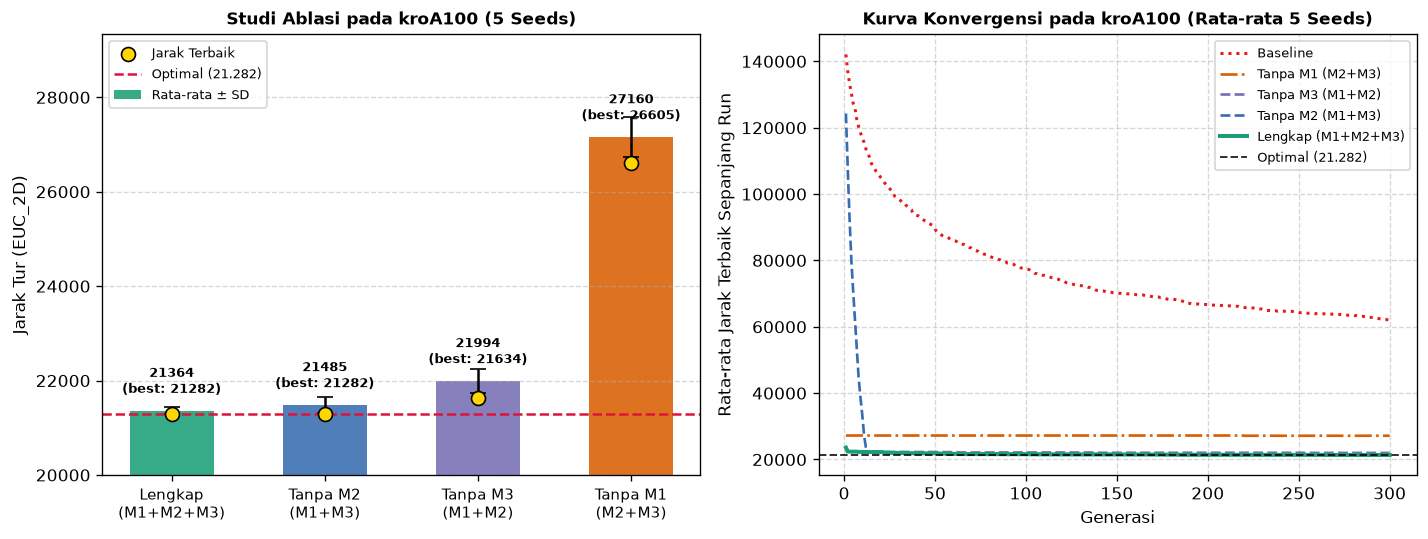

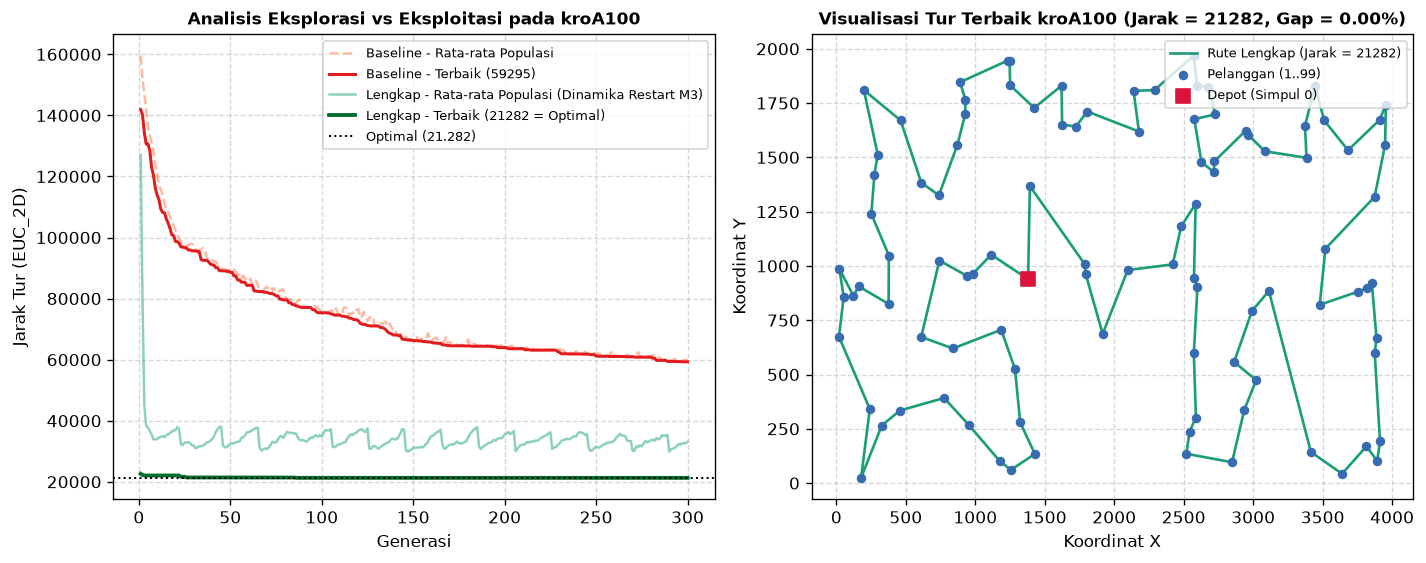

In [26]:
# Visualisasi 1: Grafik Studi Ablasi & Equal-Time pada kroA100
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

# Panel Kiri: Perbandingan 4 Konfigurasi Ablasi pada kroA100
nama_abl = ["Lengkap\n(M1+M2+M3)", "Tanpa M2\n(M1+M3)", "Tanpa M3\n(M1+M2)", "Tanpa M1\n(M2+M3)"]
kunci_abl = ["Lengkap (M1+M2+M3)", "Tanpa M2", "Tanpa M3", "Tanpa M1"]
mean_abl = [np.mean([r["jarak"] for r in HASIL_ABLASI_KRO[k]]) for k in kunci_abl]
sd_abl = [np.std([r["jarak"] for r in HASIL_ABLASI_KRO[k]], ddof=1) for k in kunci_abl]
best_abl = [min([r["jarak"] for r in HASIL_ABLASI_KRO[k]]) for k in kunci_abl]

x_pos = np.arange(len(nama_abl))
bars = axes[0].bar(x_pos, mean_abl, yerr=sd_abl, capsize=5, width=0.55,
                   color=["#1b9e77", "#386cb0", "#7570b3", "#d95f02"], alpha=0.88, label="Rata-rata ± SD")
axes[0].scatter(x_pos, best_abl, color="gold", edgecolor="black", s=70, zorder=5, label="Jarak Terbaik")
axes[0].axhline(OPTIMAL_TSPLIB["kroA100"], color="crimson", linestyle="--", lw=1.5, label="Optimal (21.282)")
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(nama_abl, fontsize=9)
axes[0].set_ylabel("Jarak Tur (EUC_2D)")
axes[0].set_title("Studi Ablasi pada kroA100 (5 Seeds)", fontweight="bold", fontsize=10)
axes[0].set_ylim(20000, max(mean_abl) * 1.08)
axes[0].grid(True, axis="y", linestyle="--", alpha=0.5)
axes[0].legend(fontsize=8, loc="upper left")
for b, m_v, b_v in zip(bars, mean_abl, best_abl):
    axes[0].text(b.get_x() + b.get_width()/2, m_v + 280, f"{m_v:.0f}\n(best: {b_v:.0f})",
                 ha="center", va="bottom", fontsize=8, fontweight="bold")

# Panel Kanan: Kurva Konvergensi Rata-rata (5 Seeds) pada kroA100
generasi_x = np.arange(1, 301)
kurva_base = np.mean([r["riwayat"]["terbaik_sepanjang_run"] for r in HASIL_BASELINE["kroA100"]], axis=0)
kurva_tanpa_m1 = np.mean([r["riwayat"]["terbaik_sepanjang_run"] for r in HASIL_ABLASI_KRO["Tanpa M1"]], axis=0)
kurva_tanpa_m3 = np.mean([r["riwayat"]["terbaik_sepanjang_run"] for r in HASIL_ABLASI_KRO["Tanpa M3"]], axis=0)
kurva_tanpa_m2 = np.mean([r["riwayat"]["terbaik_sepanjang_run"] for r in HASIL_ABLASI_KRO["Tanpa M2"]], axis=0)
kurva_lengkap = np.mean([r["riwayat"]["terbaik_sepanjang_run"] for r in HASIL_ABLASI_KRO["Lengkap (M1+M2+M3)"]], axis=0)

axes[1].plot(generasi_x, kurva_base, label="Baseline", color="#e41a1c", linestyle=":", lw=1.8)
axes[1].plot(generasi_x, kurva_tanpa_m1, label="Tanpa M1 (M2+M3)", color="#d95f02", linestyle="-.", lw=1.6)
axes[1].plot(generasi_x, kurva_tanpa_m3, label="Tanpa M3 (M1+M2)", color="#7570b3", linestyle="--", lw=1.6)
axes[1].plot(generasi_x, kurva_tanpa_m2, label="Tanpa M2 (M1+M3)", color="#386cb0", linestyle="--", lw=1.6)
axes[1].plot(generasi_x, kurva_lengkap, label="Lengkap (M1+M2+M3)", color="#1b9e77", lw=2.4)
axes[1].axhline(OPTIMAL_TSPLIB["kroA100"], color="black", linestyle="--", lw=1.2, alpha=0.8, label="Optimal (21.282)")
axes[1].set_xlabel("Generasi")
axes[1].set_ylabel("Rata-rata Jarak Terbaik Sepanjang Run")
axes[1].set_title("Kurva Konvergensi pada kroA100 (Rata-rata 5 Seeds)", fontweight="bold", fontsize=10)
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(r"C:\Users\User\.gemini\antigravity\brain\e2aec067-fb97-4e28-819b-5564ad3cc3b1\scratch\fig_ablation_convergence.png", dpi=220)
plt.show()

# Visualisasi 2: Eksplorasi vs Eksploitasi (Terbaik vs Rata-rata Populasi pada kroA100) & Rute Terbaik
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

run_kro_best = min(HASIL_LENGKAP["kroA100"], key=lambda r: r["jarak"])
run_base_best = min(HASIL_BASELINE["kroA100"], key=lambda r: r["jarak"])

axes[0].plot(generasi_x, run_base_best["riwayat"]["rata_rata"], color="#fc8d62", alpha=0.6, linestyle="--", label="Baseline - Rata-rata Populasi")
axes[0].plot(generasi_x, run_base_best["riwayat"]["terbaik_sepanjang_run"], color="#e41a1c", lw=1.8, label=f"Baseline - Terbaik ({run_base_best['jarak']:.0f})")
axes[0].plot(generasi_x, run_kro_best["riwayat"]["rata_rata"], color="#66c2a5", alpha=0.75, linestyle="-", label="Lengkap - Rata-rata Populasi (Dinamika Restart M3)")
axes[0].plot(generasi_x, run_kro_best["riwayat"]["terbaik_sepanjang_run"], color="#006d2c", lw=2.3, label=f"Lengkap - Terbaik ({run_kro_best['jarak']:.0f} = Optimal)")
axes[0].axhline(OPTIMAL_TSPLIB["kroA100"], color="black", linestyle=":", lw=1.2, label="Optimal (21.282)")
axes[0].set_xlabel("Generasi")
axes[0].set_ylabel("Jarak Tur (EUC_2D)")
axes[0].set_title("Analisis Eksplorasi vs Eksploitasi pada kroA100", fontweight="bold", fontsize=10)
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(fontsize=8, loc="upper right")

# Plot Rute Terbaik kroA100
koord_kro = KOORD_TSPLIB["kroA100"]
sol_kro = run_kro_best["solusi"]
xs = [koord_kro[i][0] for i in sol_kro]
ys = [koord_kro[i][1] for i in sol_kro]
axes[1].plot(xs, ys, color="#1b9e77", lw=1.6, zorder=2, label=f"Rute Lengkap (Jarak = {run_kro_best['jarak']:.0f})")
axes[1].scatter([c[0] for c in koord_kro[1:]], [c[1] for c in koord_kro[1:]], color="#386cb0", s=22, zorder=3, label="Pelanggan (1..99)")
axes[1].scatter([koord_kro[0][0]], [koord_kro[0][1]], color="crimson", marker="s", s=70, zorder=4, label="Depot (Simpul 0)")
axes[1].set_xlabel("Koordinat X")
axes[1].set_ylabel("Koordinat Y")
axes[1].set_title(f"Visualisasi Tur Terbaik kroA100 (Jarak = {run_kro_best['jarak']:.0f}, Gap = 0.00%)", fontweight="bold", fontsize=10)
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend(fontsize=8, loc="upper right")

plt.tight_layout()
plt.savefig(r"C:\Users\User\.gemini\antigravity\brain\e2aec067-fb97-4e28-819b-5564ad3cc3b1\scratch\fig_exploration_tour_kroA100.png", dpi=220)
plt.show()